<a href="https://colab.research.google.com/github/Gumihuy/Tugas-Infrastruktur/blob/main/Eksperimen_Paper2_1DCNN_Sine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [39]:

from google.colab import files

uploaded = files.upload()


Saving Traffic-Aware-Intelligent-Association-and-Task-Offloading-for-Multi-Access-Edge-Computing-main.zip to Traffic-Aware-Intelligent-Association-and-Task-Offloading-for-Multi-Access-Edge-Computing-main (1).zip


In [40]:

import zipfile
import os

zip_path = next(iter(uploaded.keys()))

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/paper2')

print("Berhasil mengekstrak repository!")

# Menampilkan folder utama
os.listdir('/content/paper2')


Berhasil mengekstrak repository!


['Traffic-Aware-Intelligent-Association-and-Task-Offloading-for-Multi-Access-Edge-Computing-main']

In [41]:

import os

base_path = (
    "/content/paper2/"
    "Traffic-Aware-Intelligent-Association-and-Task-Offloading-for-Multi-Access-Edge-Computing-main"
)

dataset_path = os.path.join(
    base_path,
    "2. multi-step prediction model(1DCNN)",
    "1-dataset"
)

print("Dataset folder:", dataset_path)
print("Isi dataset:", os.listdir(dataset_path))


Dataset folder: /content/paper2/Traffic-Aware-Intelligent-Association-and-Task-Offloading-for-Multi-Access-Edge-Computing-main/2. multi-step prediction model(1DCNN)/1-dataset
Isi dataset: ['userdata-3-sawtooth.csv', 'userdata-4-random (1).csv', 'userdata-2-triangle.csv', 'userdata-4-random.csv', 'userdata-3-sawtooth (1).csv', 'userdata-2-triangle (1).csv', 'userdata-1-sine (1).csv', 'userdata-1-sine.csv']


Jumlah data: 50000
10 data pertama: [0.5702 0.4884 0.5232 0.5057 0.6119 0.5728 0.6473 0.644  0.6766 0.6657]
Nilai minimum: 0.0
Nilai maksimum: 1.0


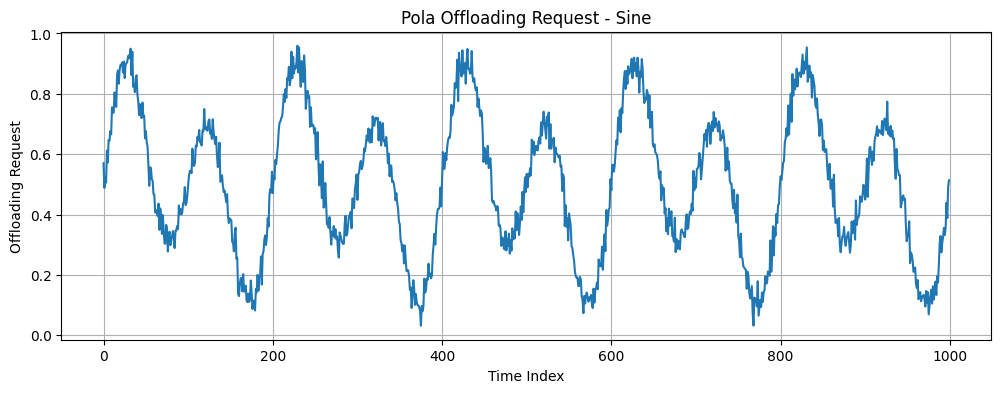

In [42]:

import numpy as np
import matplotlib.pyplot as plt
import os

sine_path = os.path.join(
    dataset_path,
    "userdata-1-sine.csv"
)

data = np.loadtxt(sine_path, delimiter=",")

print("Jumlah data:", len(data))
print("10 data pertama:", data[:10])
print("Nilai minimum:", np.min(data))
print("Nilai maksimum:", np.max(data))

plt.figure(figsize=(12, 4))
plt.plot(data[:1000])
plt.title("Pola Offloading Request - Sine")
plt.xlabel("Time Index")
plt.ylabel("Offloading Request")
plt.grid()
plt.show()


In [43]:

def to_supervisedDataset(data, lookback, horizon):
    X, y = [], []

    for i in range(len(data) - lookback - horizon):
        X.append(data[i:i+lookback].reshape(lookback, 1))
        y.append(data[i+lookback:i+lookback+horizon])

    return np.array(X), np.array(y)

def split_dataset(data, split_ratio):
    index = round(len(data) * split_ratio)
    return data[:index], data[index:]

train, test = split_dataset(data, 0.9)
train, val = split_dataset(train, 0.9)

X_train, y_train = to_supervisedDataset(train, 128, 5)
X_val, y_val = to_supervisedDataset(val, 128, 5)
X_test, y_test = to_supervisedDataset(test, 128, 5)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)


Train: (40367, 128, 1) (40367, 5)
Validation: (4367, 128, 1) (4367, 5)
Test: (4867, 128, 1) (4867, 5)


In [44]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D
from tensorflow.keras.layers import Flatten, Dense
from tensorflow.keras.optimizers import Adam

print("Perangkat tersedia:", tf.config.list_physical_devices())

model = Sequential([
    Conv1D(
        filters=16,
        kernel_size=8,
        activation="relu",
        input_shape=(128, 1)
    ),
    MaxPooling1D(pool_size=4),
    Flatten(),
    Dense(32, activation="relu"),
    Dense(8, activation="relu"),
    Dense(5, activation="linear")
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse"
)

model.summary()


Perangkat tersedia: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_1 (Conv1D)               │ (None, 121, 16)        │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 30, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 32)             │        15,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 8)              │           264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 5)              │            45 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,845 (61.89 KB)

 Trainable params: 15,845 (61.89 KB)

 Non-trainable params: 0 (0.00 B)

In [45]:

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=128,
    verbose=1
)


Epoch 1/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 0.0411 - val_loss: 0.0027
Epoch 2/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0021 - val_loss: 0.0017
Epoch 3/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0015 - val_loss: 0.0014
Epoch 4/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0013 - val_loss: 0.0013
Epoch 5/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 6/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 7/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 8/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 9/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 10/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0011 - val_loss: 0.0012


In [46]:

from sklearn.metrics import mean_squared_error, mean_absolute_error

predictions = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(
    y_test.flatten(),
    predictions.flatten()
))

mae = mean_absolute_error(
    y_test.flatten(),
    predictions.flatten()
)

print("RMSE:", rmse)
print("MAE:", mae)


153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
RMSE: 0.034900369985822195
MAE: 0.027877676063957513


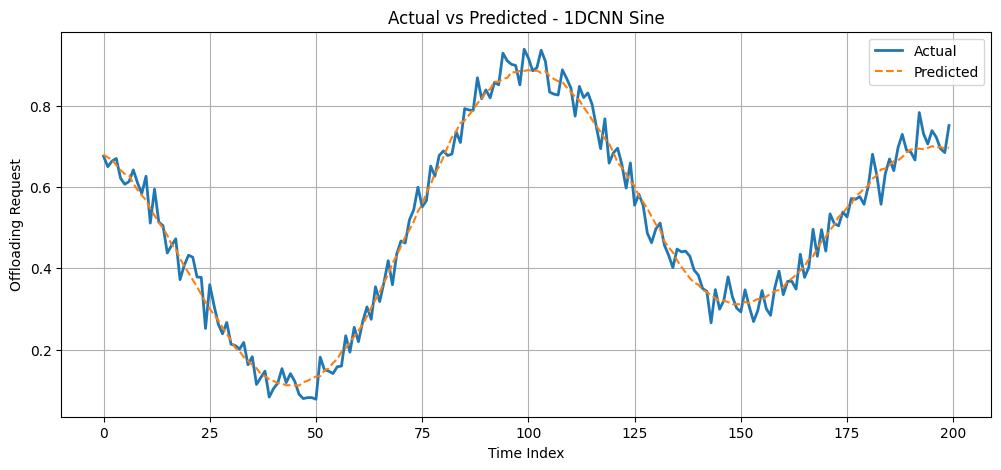

In [47]:

plt.figure(figsize=(12, 5))

plt.plot(
    y_test[:200, 0],
    label="Actual",
    linewidth=2
)

plt.plot(
    predictions[:200, 0],
    label="Predicted",
    linestyle="--"
)

plt.title("Actual vs Predicted - 1DCNN Sine")
plt.xlabel("Time Index")
plt.ylabel("Offloading Request")
plt.legend()
plt.grid()
plt.show()


In [48]:

import pandas as pd

results = pd.DataFrame({
    "Actual": y_test[:, 0],
    "Predicted": predictions[:, 0]
})

results.to_csv(
    "/content/hasil_1dcnn_sine.csv",
    index=False
)

model.save("/content/model_1dcnn_sine.keras")

print("Hasil eksperimen berhasil disimpan!")


Hasil eksperimen berhasil disimpan!


In [49]:

import os

print("CSV tersedia:",
      os.path.exists("/content/hasil_1dcnn_sine.csv"))

print("Model tersedia:",
      os.path.exists("/content/model_1dcnn_sine.keras"))

print("\nDaftar file:")
print(os.listdir("/content"))


CSV tersedia: True
Model tersedia: True

Daftar file:
['.config', 'rekap_eksperimen_1DCNN.csv', 'hasil_1dcnn_sine.csv', 'hasil_1DCNN.csv', 'model_1dcnn_sine.keras', 'paper2', 'Traffic-Aware-Intelligent-Association-and-Task-Offloading-for-Multi-Access-Edge-Computing-main (1).zip', 'perbandingan_1DCNN_LSTM.csv', 'Traffic-Aware-Intelligent-Association-and-Task-Offloading-for-Multi-Access-Edge-Computing-main.zip', 'sample_data']


In [50]:

print("Hasil Evaluasi 1DCNN - Sine")
print("============================")
print("RMSE:", rmse)
print("MAE :", mae)


Hasil Evaluasi 1DCNN - Sine
RMSE: 0.034900369985822195
MAE : 0.027877676063957513


In [51]:

from google.colab import files

files.download("/content/hasil_1dcnn_sine.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Jumlah data: 50000
Nilai minimum: 0.0
Nilai maksimum: 1.0


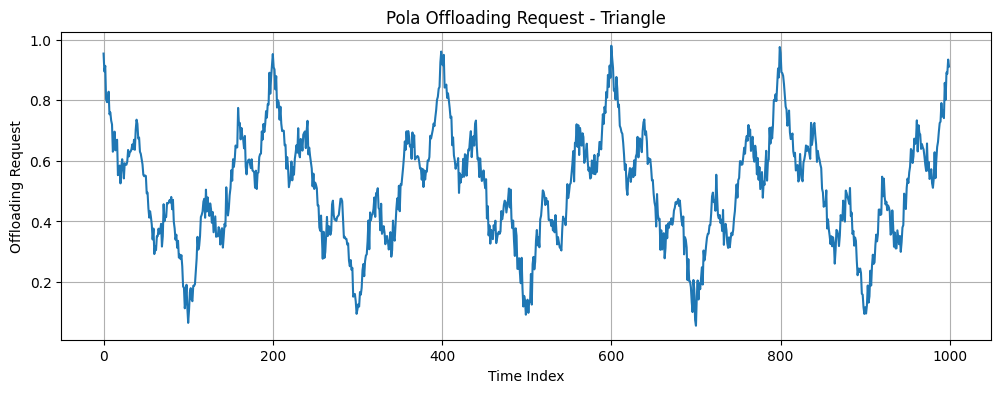

In [52]:

# Membaca dataset Triangle
triangle_path = os.path.join(
    dataset_path,
    "userdata-2-triangle.csv"
)

data_triangle = np.loadtxt(
    triangle_path,
    delimiter=","
)

print("Jumlah data:", len(data_triangle))
print("Nilai minimum:", np.min(data_triangle))
print("Nilai maksimum:", np.max(data_triangle))

plt.figure(figsize=(12, 4))
plt.plot(data_triangle[:1000])
plt.title("Pola Offloading Request - Triangle")
plt.xlabel("Time Index")
plt.ylabel("Offloading Request")
plt.grid()
plt.show()


In [53]:

train, test = split_dataset(data_triangle, 0.9)
train, val = split_dataset(train, 0.9)

X_train_tri, y_train_tri = to_supervisedDataset(train, 128, 5)
X_val_tri, y_val_tri = to_supervisedDataset(val, 128, 5)
X_test_tri, y_test_tri = to_supervisedDataset(test, 128, 5)

print("Train:", X_train_tri.shape, y_train_tri.shape)
print("Validation:", X_val_tri.shape, y_val_tri.shape)
print("Test:", X_test_tri.shape, y_test_tri.shape)


Train: (40367, 128, 1) (40367, 5)
Validation: (4367, 128, 1) (4367, 5)
Test: (4867, 128, 1) (4867, 5)


In [54]:

model_tri = tf.keras.models.clone_model(model)

model_tri.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

history_tri = model_tri.fit(
    X_train_tri,
    y_train_tri,
    validation_data=(X_val_tri, y_val_tri),
    epochs=10,
    batch_size=128,
    verbose=1
)


Epoch 1/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.0203 - val_loss: 0.0013
Epoch 2/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 3/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 4/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0012 - val_loss: 0.0011
Epoch 5/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0011 - val_loss: 0.0012
Epoch 6/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0011 - val_loss: 0.0011
Epoch 7/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0011 - val_loss: 0.0011
Epoch 8/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0011 - val_loss: 0.0011
Epoch 9/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0011 - val_loss: 0.0011
Epoch 10/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0011 - val_loss: 0.0011


In [55]:

predictions_tri = model_tri.predict(X_test_tri)

rmse_tri = np.sqrt(mean_squared_error(
    y_test_tri.flatten(),
    predictions_tri.flatten()
))

mae_tri = mean_absolute_error(
    y_test_tri.flatten(),
    predictions_tri.flatten()
)

print("Hasil Evaluasi 1DCNN - Triangle")
print("RMSE:", rmse_tri)
print("MAE:", mae_tri)


153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Hasil Evaluasi 1DCNN - Triangle
RMSE: 0.03363046474779782
MAE: 0.026950906088395312


Jumlah data: 50000
Minimum: 0.0
Maksimum: 1.0


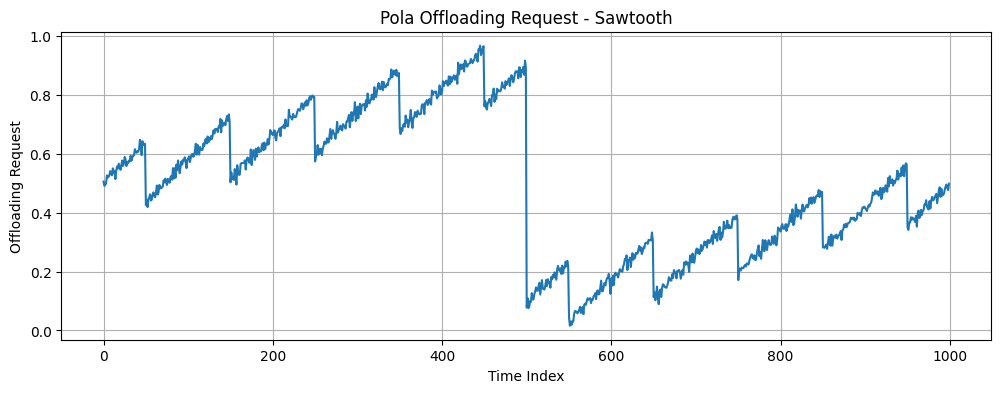

In [56]:

data_saw = np.loadtxt(
    os.path.join(dataset_path, "userdata-3-sawtooth.csv"),
    delimiter=","
)

print("Jumlah data:", len(data_saw))
print("Minimum:", np.min(data_saw))
print("Maksimum:", np.max(data_saw))

plt.figure(figsize=(12, 4))
plt.plot(data_saw[:1000])
plt.title("Pola Offloading Request - Sawtooth")
plt.xlabel("Time Index")
plt.ylabel("Offloading Request")
plt.grid()
plt.show()


In [57]:

train, test = split_dataset(data_saw, 0.9)
train, val = split_dataset(train, 0.9)

X_train_saw, y_train_saw = to_supervisedDataset(train, 128, 5)
X_val_saw, y_val_saw = to_supervisedDataset(val, 128, 5)
X_test_saw, y_test_saw = to_supervisedDataset(test, 128, 5)

print("Train:", X_train_saw.shape)
print("Validation:", X_val_saw.shape)
print("Test:", X_test_saw.shape)


Train: (40367, 128, 1)
Validation: (4367, 128, 1)
Test: (4867, 128, 1)


In [58]:

model_saw = tf.keras.models.clone_model(model)

model_saw.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

history_saw = model_saw.fit(
    X_train_saw,
    y_train_saw,
    validation_data=(X_val_saw, y_val_saw),
    epochs=10,
    batch_size=128,
    verbose=1
)


Epoch 1/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.0458 - val_loss: 0.0044
Epoch 2/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0040 - val_loss: 0.0032
Epoch 3/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0032 - val_loss: 0.0029
Epoch 4/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0028 - val_loss: 0.0024
Epoch 5/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0025 - val_loss: 0.0023
Epoch 6/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0024 - val_loss: 0.0021
Epoch 7/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0022 - val_loss: 0.0021
Epoch 8/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0021 - val_loss: 0.0021
Epoch 9/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0019 - val_loss: 0.0018
Epoch 10/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0019 - val_loss: 0.0017


In [59]:

predictions_saw = model_saw.predict(X_test_saw)

rmse_saw = np.sqrt(mean_squared_error(
    y_test_saw.flatten(),
    predictions_saw.flatten()
))

mae_saw = mean_absolute_error(
    y_test_saw.flatten(),
    predictions_saw.flatten()
)

print("Hasil Evaluasi 1DCNN - Sawtooth")
print("RMSE:", rmse_saw)
print("MAE:", mae_saw)


153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Hasil Evaluasi 1DCNN - Sawtooth
RMSE: 0.041709944214769396
MAE: 0.020635301454183328


Jumlah data: 50000
Minimum: 0.0
Maksimum: 1.0


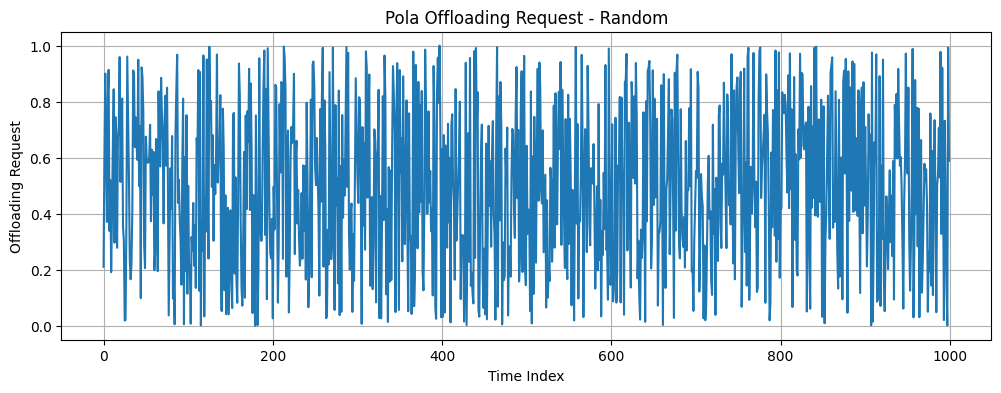

In [60]:

data_random = np.loadtxt(
    os.path.join(dataset_path, "userdata-4-random.csv"),
    delimiter=","
)

print("Jumlah data:", len(data_random))
print("Minimum:", np.min(data_random))
print("Maksimum:", np.max(data_random))

plt.figure(figsize=(12, 4))
plt.plot(data_random[:1000])
plt.title("Pola Offloading Request - Random")
plt.xlabel("Time Index")
plt.ylabel("Offloading Request")
plt.grid()
plt.show()


In [61]:

train, test = split_dataset(data_random, 0.9)
train, val = split_dataset(train, 0.9)

X_train_rand, y_train_rand = to_supervisedDataset(train, 128, 5)
X_val_rand, y_val_rand = to_supervisedDataset(val, 128, 5)
X_test_rand, y_test_rand = to_supervisedDataset(test, 128, 5)

print("Train:", X_train_rand.shape)
print("Validation:", X_val_rand.shape)
print("Test:", X_test_rand.shape)


Train: (40367, 128, 1)
Validation: (4367, 128, 1)
Test: (4867, 128, 1)


In [62]:

model_rand = tf.keras.models.clone_model(model)

model_rand.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="mse"
)

history_rand = model_rand.fit(
    X_train_rand,
    y_train_rand,
    validation_data=(X_val_rand, y_val_rand),
    epochs=10,
    batch_size=128,
    verbose=1
)


Epoch 1/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: 0.0866 - val_loss: 0.0850
Epoch 2/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0840 - val_loss: 0.0842
Epoch 3/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0837 - val_loss: 0.0845
Epoch 4/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0835 - val_loss: 0.0841
Epoch 5/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0833 - val_loss: 0.0840
Epoch 6/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0833 - val_loss: 0.0840
Epoch 7/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0831 - val_loss: 0.0839
Epoch 8/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0829 - val_loss: 0.0840
Epoch 9/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0829 - val_loss: 0.0839
Epoch 10/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0829 - val_loss: 0.0842


In [63]:

predictions_rand = model_rand.predict(X_test_rand)

rmse_rand = np.sqrt(mean_squared_error(
    y_test_rand.flatten(),
    predictions_rand.flatten()
))

mae_rand = mean_absolute_error(
    y_test_rand.flatten(),
    predictions_rand.flatten()
)

print("Hasil Evaluasi 1DCNN - Random")
print("RMSE:", rmse_rand)
print("MAE:", mae_rand)


153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Hasil Evaluasi 1DCNN - Random
RMSE: 0.28840379869428096
MAE: 0.24853862151693412


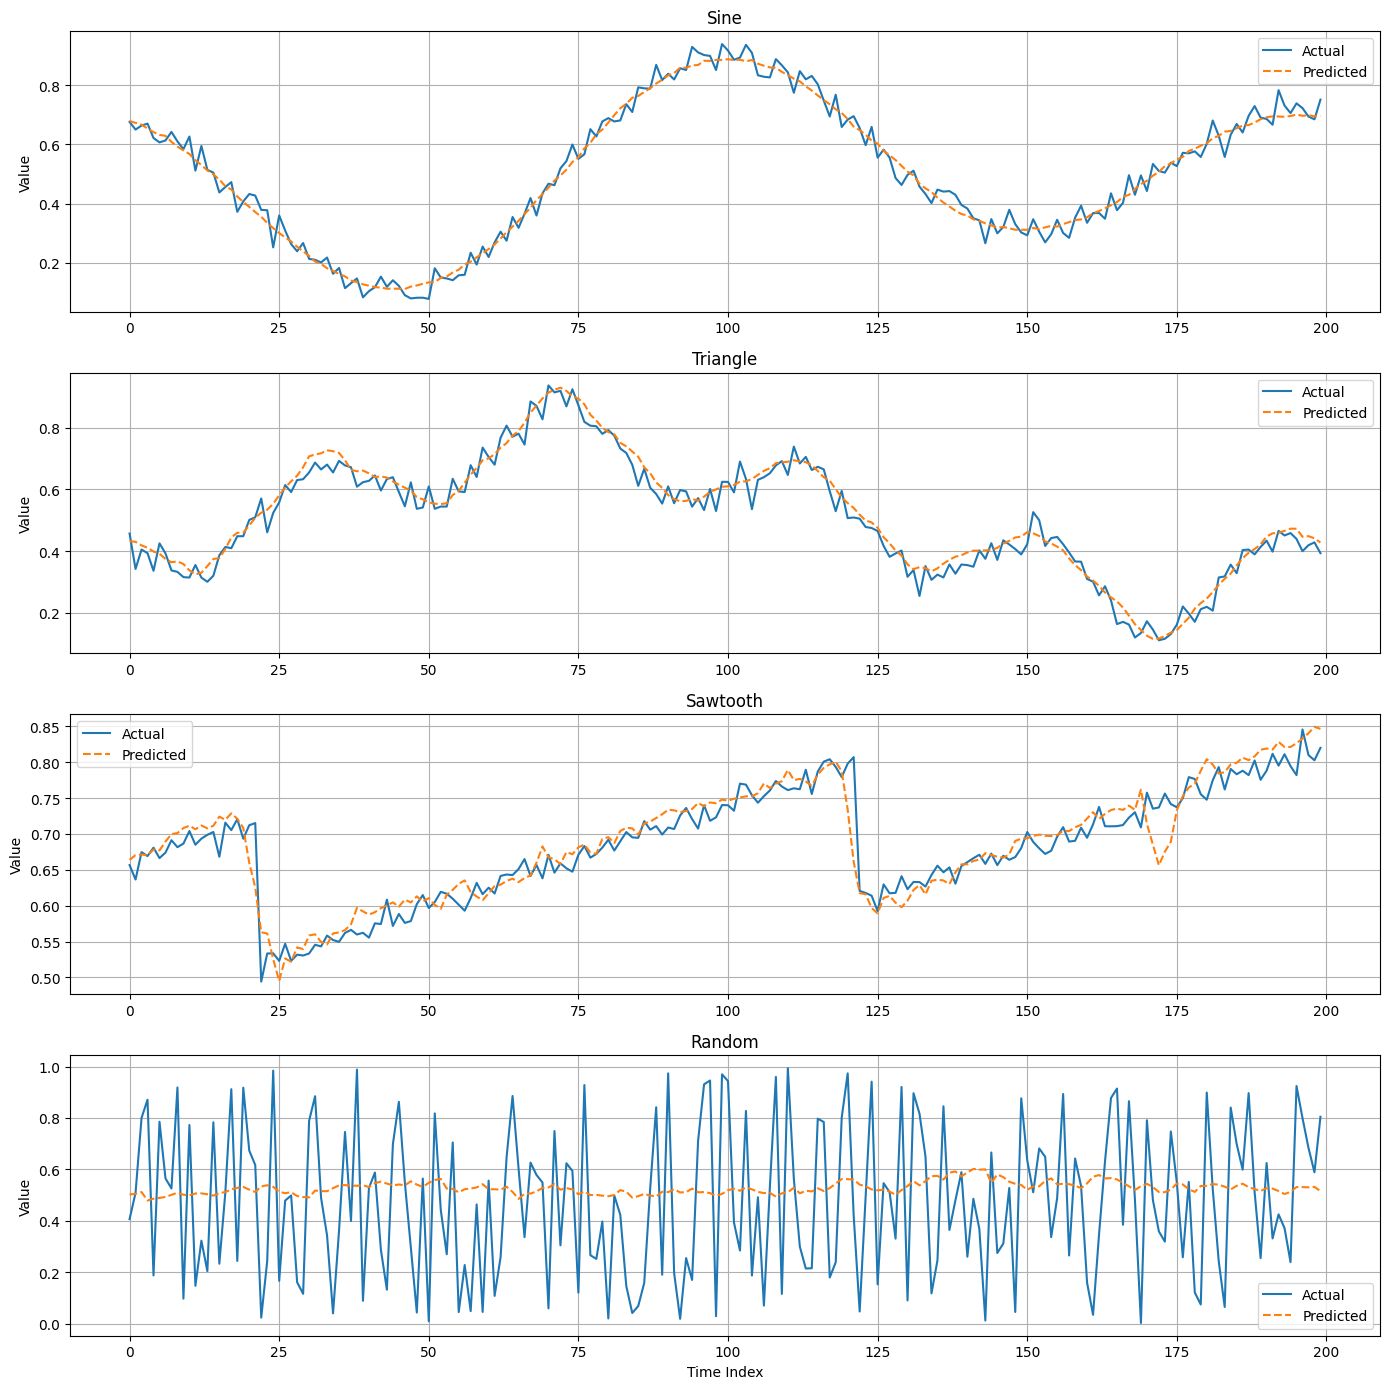

In [64]:

# Membandingkan hasil prediksi seluruh dataset

datasets = [
    ("Sine", y_test, predictions),
    ("Triangle", y_test_tri, predictions_tri),
    ("Sawtooth", y_test_saw, predictions_saw),
    ("Random", y_test_rand, predictions_rand)
]

fig, axes = plt.subplots(4, 1, figsize=(14, 14))

for ax, (name, actual, predicted) in zip(axes, datasets):
    ax.plot(actual[:200, 0], label="Actual")
    ax.plot(predicted[:200, 0], label="Predicted", linestyle="--")
    ax.set_title(name)
    ax.set_ylabel("Value")
    ax.legend()
    ax.grid()

plt.xlabel("Time Index")
plt.tight_layout()
plt.show()


In [65]:

results_all = pd.DataFrame({
    "Dataset": ["Sine", "Triangle", "Sawtooth", "Random"],
    "Model": ["1DCNN"] * 4,
    "RMSE": [rmse, rmse_tri, rmse_saw, rmse_rand],
    "MAE": [mae, mae_tri, mae_saw, mae_rand]
})

results_all.to_csv(
    "/content/rekap_eksperimen_1DCNN.csv",
    index=False
)

display(results_all)

from google.colab import files
files.download("/content/rekap_eksperimen_1DCNN.csv")


,Dataset,Model,RMSE,MAE
0,Sine,1DCNN,0.034900,0.027878
1,Triangle,1DCNN,0.033630,0.026951
2,Sawtooth,1DCNN,0.041710,0.020635
3,Random,1DCNN,0.288404,0.248539


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

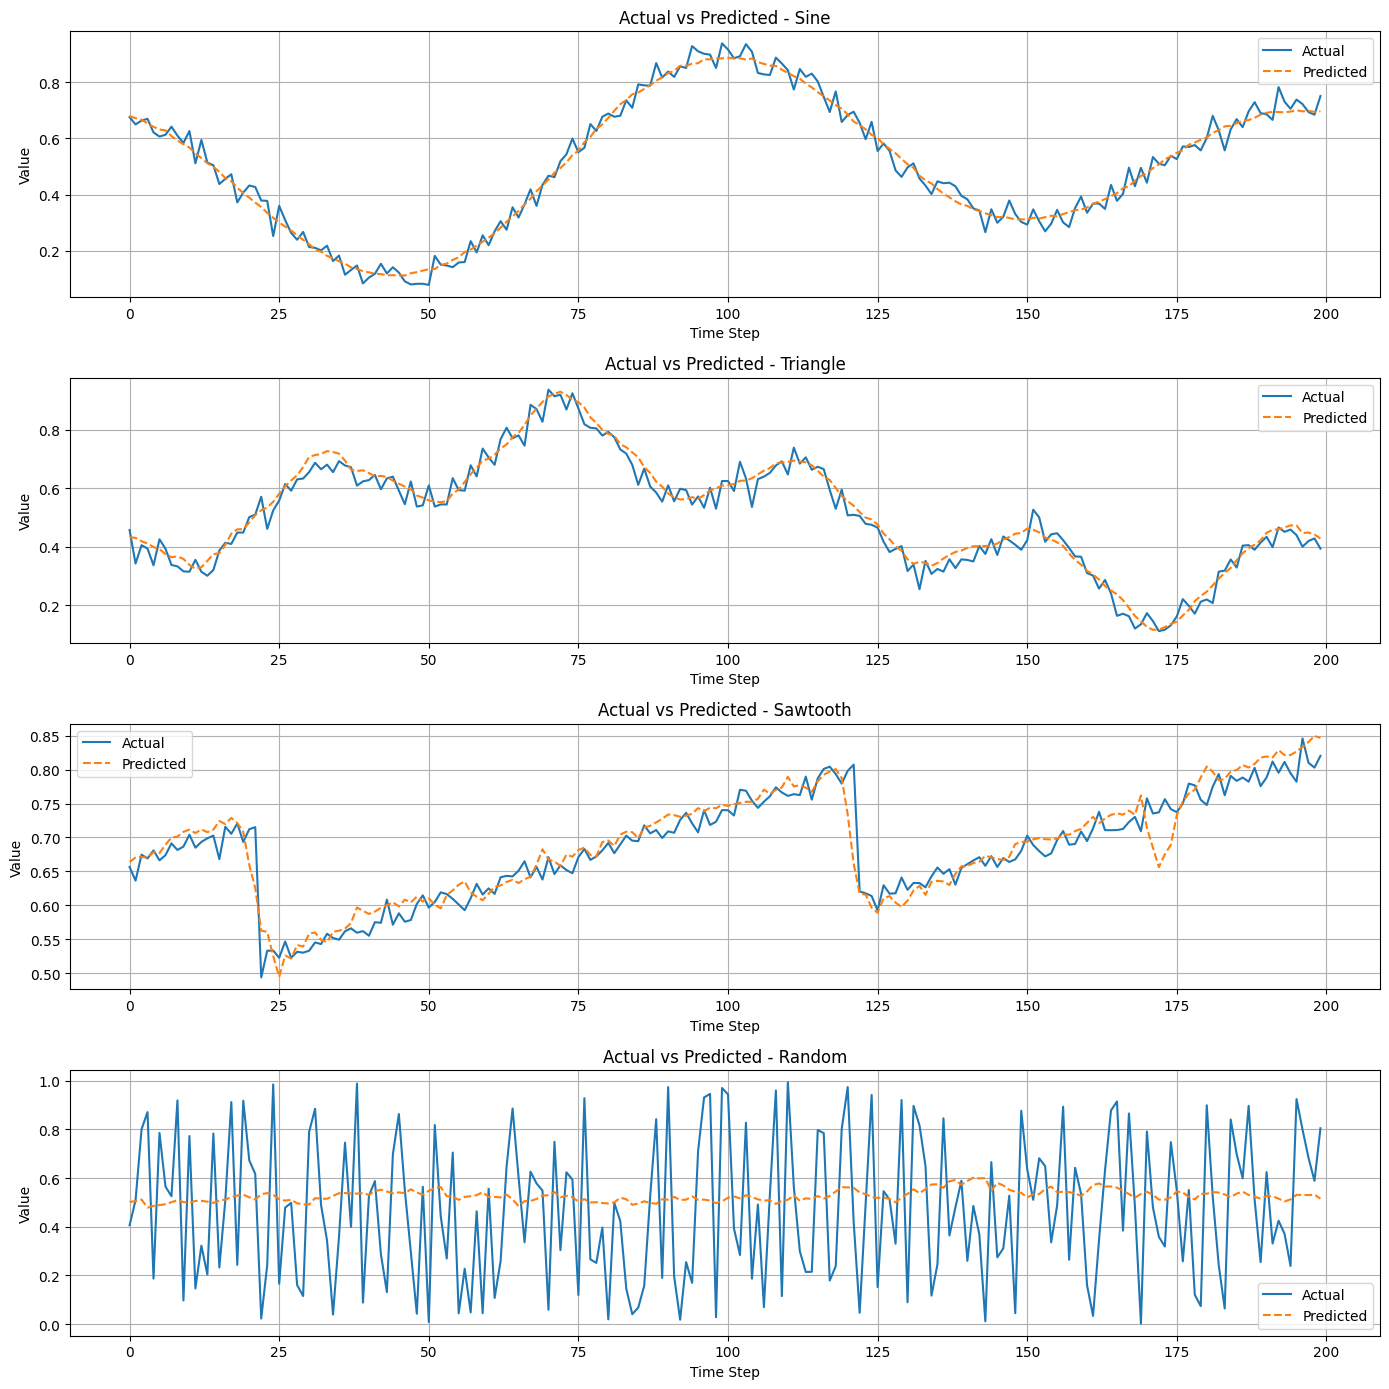

In [66]:
datasets = [
    ("Sine", y_test, predictions),
    ("Triangle", y_test_tri, predictions_tri),
    ("Sawtooth", y_test_saw, predictions_saw),
    ("Random", y_test_rand, predictions_rand)
]

fig, axes = plt.subplots(4, 1, figsize=(14, 14))

for ax, (name, actual, predicted) in zip(axes, datasets):
    ax.plot(actual[:200, 0], label="Actual")
    ax.plot(predicted[:200, 0], label="Predicted", linestyle="--")

    ax.set_title(f"Actual vs Predicted - {name}")
    ax.set_xlabel("Time Step")
    ax.set_ylabel("Value")
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

In [67]:
for name, actual, predicted in [
    ("Sine", y_test, predictions),
    ("Triangle", y_test_tri, predictions_tri),
    ("Sawtooth", y_test_saw, predictions_saw),
    ("Random", y_test_rand, predictions_rand)
]:
    print(f"\n===== {name} =====")
    print("Actual     :", actual[:10, 0])
    print("Predicted  :", predicted[:10, 0])


===== Sine =====
Actual     : [0.6758 0.6499 0.6636 0.67   0.6214 0.6067 0.6131 0.642  0.61   0.5838]
Predicted  : [0.6788524  0.6727182  0.666638   0.653569   0.64134014 0.63187796
 0.6287785  0.60836715 0.5926551  0.5794564 ]

===== Triangle =====
Actual     : [0.4571 0.3425 0.4053 0.3936 0.3365 0.4254 0.393  0.3376 0.333  0.3159]
Predicted  : [0.43252313 0.4302851  0.41876447 0.41115555 0.3989349  0.39157918
 0.37494084 0.36417344 0.36705557 0.3583879 ]

===== Sawtooth =====
Actual     : [0.6566 0.6365 0.6747 0.6692 0.6809 0.6664 0.674  0.6913 0.6816 0.6866]
Predicted  : [0.6638739  0.67055154 0.6714943  0.67010736 0.6783342  0.67706186
 0.68944657 0.69983095 0.7012525  0.70828456]

===== Random =====
Actual     : [0.4063 0.5087 0.8003 0.8709 0.1871 0.7853 0.5648 0.5256 0.9186 0.097 ]
Predicted  : [0.50225544 0.5047969  0.51167464 0.47858933 0.4858515  0.48889065
 0.4925594  0.50093716 0.5089906  0.501278  ]


In [68]:
for name, actual, predicted in [
    ("Sine", y_test, predictions),
    ("Triangle", y_test_tri, predictions_tri),
    ("Sawtooth", y_test_saw, predictions_saw),
    ("Random", y_test_rand, predictions_rand)
]:
    error = actual.flatten() - predicted.flatten()

    print(f"\n===== {name} =====")
    print("Mean Error :", error.mean())
    print("Max Error  :", abs(error).max())
    print("Min Actual :", actual.min())
    print("Max Actual :", actual.max())
    print("Min Predict:", predicted.min())
    print("Max Predict:", predicted.max())


===== Sine =====
Mean Error : 0.005939823719292714
Max Error  : 0.14732486009597778
Min Actual : 0.0222
Max Actual : 1.0
Min Predict: 0.07903524
Max Predict: 0.90652424

===== Triangle =====
Mean Error : 0.0015068420116260157
Max Error  : 0.16063107280731204
Min Actual : 0.0279
Max Actual : 1.0
Min Predict: 0.08612702
Max Predict: 0.9346843

===== Sawtooth =====
Mean Error : -0.0007086440221587804
Max Error  : 0.6106902221679688
Min Actual : 0.0081
Max Actual : 0.9949
Min Predict: 0.033332117
Max Predict: 0.9932086

===== Random =====
Mean Error : -0.013987317543443232
Max Error  : 0.5880858047485351
Min Actual : 0.0001
Max Actual : 0.9998
Min Predict: 0.3834629
Max Predict: 0.6141604


In [69]:
datasets = [
    ("Sine", y_test, predictions),
    ("Triangle", y_test_tri, predictions_tri),
    ("Sawtooth", y_test_saw, predictions_saw),
    ("Random", y_test_rand, predictions_rand)
]

for name, actual, predicted in datasets:
    error = actual.flatten() - predicted.flatten()

    print(f"\n===== {name} =====")
    print("MAE              :", abs(error).mean())
    print("Median Error     :", np.median(abs(error)))
    print("90th Percentile  :", np.percentile(abs(error), 90))
    print("95th Percentile  :", np.percentile(abs(error), 95))
    print("Prediksi < 0     :", np.sum(predicted < 0))
    print("Prediksi > 1     :", np.sum(predicted > 1))


===== Sine =====
MAE              : 0.027877676063957513
Median Error     : 0.02360491733551029
90th Percentile  : 0.05700628417968752
95th Percentile  : 0.06779948073387149
Prediksi < 0     : 0
Prediksi > 1     : 0

===== Triangle =====
MAE              : 0.026950906088395312
Median Error     : 0.022941595077514698
90th Percentile  : 0.05503244062423704
95th Percentile  : 0.06621803664207458
Prediksi < 0     : 0
Prediksi > 1     : 0

===== Sawtooth =====
MAE              : 0.020635301454183328
Median Error     : 0.013658428573608439
90th Percentile  : 0.03652909973144535
95th Percentile  : 0.04974806651592253
Prediksi < 0     : 0
Prediksi > 1     : 0

===== Random =====
MAE              : 0.24853862151693412
Median Error     : 0.24872812147140505
90th Percentile  : 0.448923138256073
95th Percentile  : 0.47670744195461273
Prediksi < 0     : 0
Prediksi > 1     : 0


In [70]:
import pandas as pd

hasil_1dcnn = pd.DataFrame({
    "Dataset": ["Sine", "Triangle", "Sawtooth", "Random"],
    "Model": ["1DCNN"] * 4,
    "RMSE": [rmse, rmse_tri, rmse_saw, rmse_rand],
    "MAE": [mae, mae_tri, mae_saw, mae_rand]
})

hasil_1dcnn.to_csv(
    "/content/hasil_1DCNN.csv",
    index=False
)

display(hasil_1dcnn)

,Dataset,Model,RMSE,MAE
0,Sine,1DCNN,0.034900,0.027878
1,Triangle,1DCNN,0.033630,0.026951
2,Sawtooth,1DCNN,0.041710,0.020635
3,Random,1DCNN,0.288404,0.248539


In [71]:
%whos

Variable                   Type          Data/Info
--------------------------------------------------
Adam                       type          <class 'keras.src.optimizers.adam.Adam'>
Add                        type          <class 'keras.src.layers.merging.add.Add'>
Conv1D                     type          <class 'keras.src.layers.<...>olutional.conv1d.Conv1D'>
Dense                      type          <class 'keras.src.layers.core.dense.Dense'>
Embedding                  type          <class 'keras.src.layers.<...>ore.embedding.Embedding'>
Flatten                    type          <class 'keras.src.layers.<...>shaping.flatten.Flatten'>
GlobalAveragePooling1D     type          <class 'keras.src.layers.<...>.GlobalAveragePooling1D'>
Input                      function      <function Input at 0x7fe0e200e340>
LSTM                       type          <class 'keras.src.layers.rnn.lstm.LSTM'>
LayerNormalization         type          <class 'keras.src.layers.<...>tion.LayerNormalization'>
MaxP

In [72]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input
from tensorflow.keras.optimizers import Adam

def create_lstm_model():
    model = Sequential([
        Input(shape=(128, 1)),
        LSTM(50, activation="tanh"),
        Dense(32, activation="relu"),
        Dense(8, activation="relu"),
        Dense(5, activation="linear")
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"]
    )

    return model

print("Model LSTM berhasil dibuat!")

Model LSTM berhasil dibuat!


In [73]:
datasets_lstm = [
    ("Sine", X_train, y_train, X_val, y_val, X_test, y_test),
    ("Triangle", X_train_tri, y_train_tri, X_val_tri, y_val_tri, X_test_tri, y_test_tri),
    ("Sawtooth", X_train_saw, y_train_saw, X_val_saw, y_val_saw, X_test_saw, y_test_saw),
    ("Random", X_train_rand, y_train_rand, X_val_rand, y_val_rand, X_test_rand, y_test_rand)
]

hasil_lstm = []

models_lstm = {}
predictions_lstm = {}

for name, Xtr, ytr, Xv, yv, Xte, yte in datasets_lstm:

    print(f"\n===== Training LSTM: {name} =====")

    model_lstm = create_lstm_model()

    history_lstm = model_lstm.fit(
        Xtr, ytr,
        validation_data=(Xv, yv),
        epochs=10,
        batch_size=128,
        verbose=1
    )

    pred = model_lstm.predict(Xte, verbose=0)

    error = yte.flatten() - pred.flatten()

    rmse_value = np.sqrt(np.mean(error ** 2))
    mae_value = np.mean(np.abs(error))

    models_lstm[name] = model_lstm
    predictions_lstm[name] = pred

    hasil_lstm.append({
        "Dataset": name,
        "Model": "LSTM",
        "RMSE": rmse_value,
        "MAE": mae_value
    })

    print("RMSE:", rmse_value)
    print("MAE :", mae_value)

hasil_lstm_df = pd.DataFrame(hasil_lstm)

display(hasil_lstm_df)


===== Training LSTM: Sine =====
Epoch 1/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 0.0728 - mae: 0.1570 - val_loss: 0.0016 - val_mae: 0.0323
Epoch 2/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0015 - mae: 0.0305 - val_loss: 0.0014 - val_mae: 0.0295
Epoch 3/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - loss: 0.0014 - mae: 0.0294 - val_loss: 0.0013 - val_mae: 0.0289
Epoch 4/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0013 - mae: 0.0286 - val_loss: 0.0013 - val_mae: 0.0282
Epoch 5/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0012 - mae: 0.0280 - val_loss: 0.0012 - val_mae: 0.0279
Epoch 6/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0012 - mae: 0.0276 - val_loss: 0.0012 - val_mae: 0.0278
Epoch 7/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - loss: 0.0012 - mae: 0.0274 - val_loss: 0.0012 - val_mae: 0.0277
Epoch 8/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0012 - mae: 0.0274 - val_loss: 0.0012 - val_mae: 0.0272
Epoch 9/10
316/3

,Dataset,Model,RMSE,MAE
0,Sine,LSTM,0.035065,0.028013
1,Triangle,LSTM,0.035031,0.027980
2,Sawtooth,LSTM,0.058212,0.028877
3,Random,LSTM,0.286894,0.247615


In [74]:
# Gabungkan hasil 1DCNN dan LSTM
perbandingan_model = pd.concat(
    [hasil_1dcnn, hasil_lstm_df],
    ignore_index=True
)

# Urutkan berdasarkan dataset dan model
perbandingan_model = perbandingan_model.sort_values(
    by=["Dataset", "Model"]
).reset_index(drop=True)

display(perbandingan_model)

# Simpan ke CSV
perbandingan_model.to_csv(
    "/content/perbandingan_1DCNN_LSTM.csv",
    index=False
)

print("Hasil perbandingan berhasil disimpan!")

,Dataset,Model,RMSE,MAE
0,Random,1DCNN,0.288404,0.248539
1,Random,LSTM,0.286894,0.247615
2,Sawtooth,1DCNN,0.041710,0.020635
3,Sawtooth,LSTM,0.058212,0.028877
4,Sine,1DCNN,0.034900,0.027878
5,Sine,LSTM,0.035065,0.028013
6,Triangle,1DCNN,0.033630,0.026951
7,Triangle,LSTM,0.035031,0.027980


Hasil perbandingan berhasil disimpan!


In [75]:

import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Dense, LayerNormalization,
    MultiHeadAttention, GlobalAveragePooling1D,
    Embedding, Add
)
from tensorflow.keras.optimizers import Adam


def create_transformer_model():

    inputs = Input(shape=(128, 1))

    # Mengubah input menjadi embedding
    x = Dense(32)(inputs)

    # Menambahkan Positional Encoding
    positions = tf.range(start=0, limit=128, delta=1)
    position_embedding = Embedding(
        input_dim=128,
        output_dim=32
    )(positions)

    x = Add()([x, position_embedding])

    # Transformer Encoder
    attention = MultiHeadAttention(
        num_heads=4,
        key_dim=8
    )(x, x)

    x = LayerNormalization(epsilon=1e-6)(x + attention)

    # Feed Forward Network
    ff = Dense(64, activation="relu")(x)
    ff = Dense(32)(ff)

    x = LayerNormalization(epsilon=1e-6)(x + ff)

    # Mengubah representasi menjadi output prediksi
    x = GlobalAveragePooling1D()(x)

    x = Dense(32, activation="relu")(x)
    x = Dense(8, activation="relu")(x)

    outputs = Dense(5, activation="linear")(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"]
    )

    return model


transformer_pe_test = create_transformer_model()

transformer_pe_test.summary()


Model: "functional_18"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_12      │ (None, 128, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_42 (Dense)    │ (None, 128, 32)   │         64 │ input_layer_12[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_6 (Add)         │ (128, 128, 32)    │          0 │ dense_42[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (128, 128, 32)    │      4,224 │ add_6[0][0],      │
│ (MultiHeadAttentio… │                   │            │ add_6[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_7 (Add)         │ (128, 128, 32)    │          0 │ add_6[0][0],      │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (128, 128, 32)    │         64 │ add_7[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_43 (Dense)    │ (128, 128, 64)    │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_44 (Dense)    │ (128, 128, 32)    │      2,080 │ dense_43[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_8 (Add)         │ (128, 128, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ dense_44[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (128, 128, 32)    │         64 │ add_8[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (128, 32)         │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_45 (Dense)    │ (128, 32)         │      1,056 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_46 (Dense)    │ (128, 8)          │        264 │ dense_45[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_47 (Dense)    │ (128, 5)          │         45 │ dense_46[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 9,973 (38.96 KB)

 Trainable params: 9,973 (38.96 KB)

 Non-trainable params: 0 (0.00 B)

In [78]:

import tensorflow as tf

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Dense, LayerNormalization,
    MultiHeadAttention, GlobalAveragePooling1D,
    Embedding, Add
)
from tensorflow.keras.optimizers import Adam


def create_transformer_model():

    inputs = Input(shape=(128, 1))

    # Input embedding
    x = Dense(32)(inputs)

    # Positional Encoding
    positions = tf.range(128)

    position_embedding = Embedding(
        input_dim=128,
        output_dim=32
    )(positions)

    # Menambahkan informasi posisi
    x = Add()([x, position_embedding])

    # Transformer Encoder
    attention = MultiHeadAttention(
        num_heads=4,
        key_dim=8
    )(x, x)

    x = LayerNormalization(epsilon=1e-6)(x + attention)

    # Feed Forward Network
    ff = Dense(64, activation="relu")(x)
    ff = Dense(32)(ff)

    x = LayerNormalization(epsilon=1e-6)(x + ff)

    # Output prediction
    x = GlobalAveragePooling1D()(x)

    x = Dense(32, activation="relu")(x)
    x = Dense(8, activation="relu")(x)

    outputs = Dense(5, activation="linear")(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"]
    )

    return model


transformer_pe_test = create_transformer_model()

transformer_pe_test.summary()


Model: "functional_19"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_13      │ (None, 128, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_48 (Dense)    │ (None, 128, 32)   │         64 │ input_layer_13[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_9 (Add)         │ (128, 128, 32)    │          0 │ dense_48[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (128, 128, 32)    │      4,224 │ add_9[0][0],      │
│ (MultiHeadAttentio… │                   │            │ add_9[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_10 (Add)        │ (128, 128, 32)    │          0 │ add_9[0][0],      │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (128, 128, 32)    │         64 │ add_10[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_49 (Dense)    │ (128, 128, 64)    │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_50 (Dense)    │ (128, 128, 32)    │      2,080 │ dense_49[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_11 (Add)        │ (128, 128, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ dense_50[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (128, 128, 32)    │         64 │ add_11[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (128, 32)         │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_51 (Dense)    │ (128, 32)         │      1,056 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_52 (Dense)    │ (128, 8)          │        264 │ dense_51[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_53 (Dense)    │ (128, 5)          │         45 │ dense_52[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 9,973 (38.96 KB)

 Trainable params: 9,973 (38.96 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
%whos

In [79]:

# ============================================================
# 1. IMPORT LIBRARY
# ============================================================

import tensorflow as tf
import numpy as np
import pandas as pd

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Dense,
    LayerNormalization,
    MultiHeadAttention,
    GlobalAveragePooling1D,
    Embedding,
    Layer
)

from tensorflow.keras.optimizers import Adam

from sklearn.metrics import mean_squared_error, mean_absolute_error


# ============================================================
# 2. CUSTOM POSITIONAL ENCODING
# ============================================================

class PositionalEncoding(Layer):

    def __init__(self, sequence_length, embedding_dim, **kwargs):
        super().__init__(**kwargs)

        self.sequence_length = sequence_length
        self.embedding_dim = embedding_dim

        self.position_embedding = Embedding(
            input_dim=sequence_length,
            output_dim=embedding_dim
        )

    def call(self, inputs):

        positions = tf.range(
            start=0,
            limit=self.sequence_length,
            delta=1
        )

        position_embeddings = self.position_embedding(positions)

        # Shape (128, 32) menjadi (1, 128, 32)
        position_embeddings = tf.expand_dims(
            position_embeddings,
            axis=0
        )

        return inputs + position_embeddings

    def compute_output_shape(self, input_shape):
        return input_shape


# ============================================================
# 3. MEMBUAT ARSITEKTUR TRANSFORMER-PE
# ============================================================

def create_transformer_model():

    inputs = Input(shape=(128, 1))

    # Input Embedding
    x = Dense(32)(inputs)

    # Positional Encoding
    x = PositionalEncoding(
        sequence_length=128,
        embedding_dim=32
    )(x)

    # Multi-Head Attention
    attention = MultiHeadAttention(
        num_heads=4,
        key_dim=8
    )(x, x)

    # Residual Connection + Layer Normalization
    x = LayerNormalization(epsilon=1e-6)(x + attention)

    # Feed Forward Network
    ff = Dense(64, activation="relu")(x)
    ff = Dense(32)(ff)

    # Residual Connection + Layer Normalization
    x = LayerNormalization(epsilon=1e-6)(x + ff)

    # Global Average Pooling
    x = GlobalAveragePooling1D()(x)

    # Fully Connected Layers
    x = Dense(32, activation="relu")(x)
    x = Dense(8, activation="relu")(x)

    # Output prediksi 5 langkah
    outputs = Dense(5, activation="linear")(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="mse",
        metrics=["mae"]
    )

    return model


# ============================================================
# 4. CEK ARSITEKTUR MODEL
# ============================================================

transformer_pe_test = create_transformer_model()

transformer_pe_test.summary()

print("\nInput Shape :", transformer_pe_test.input_shape)
print("Output Shape:", transformer_pe_test.output_shape)


# ============================================================
# 5. MENYIAPKAN DATASET
# ============================================================

datasets_pe = {

    "Sine": (
        X_train, y_train,
        X_val, y_val,
        X_test, y_test
    ),

    "Triangle": (
        X_train_tri, y_train_tri,
        X_val_tri, y_val_tri,
        X_test_tri, y_test_tri
    ),

    "Sawtooth": (
        X_train_saw, y_train_saw,
        X_val_saw, y_val_saw,
        X_test_saw, y_test_saw
    ),

    "Random": (
        X_train_rand, y_train_rand,
        X_val_rand, y_val_rand,
        X_test_rand, y_test_rand
    )
}


# ============================================================
# 6. TRAINING DAN EVALUASI TRANSFORMER-PE
# ============================================================

hasil_transformer_pe = []

models_transformer_pe = {}

predictions_transformer_pe = {}

histories_transformer_pe = {}


for nama, (Xtr, ytr, Xv, yv, Xte, yte) in datasets_pe.items():

    print("\n" + "=" * 60)
    print(f"TRAINING TRANSFORMER-PE: {nama}")
    print("=" * 60)

    # Membuat model baru untuk setiap dataset
    model = create_transformer_model()

    # Training
    history = model.fit(
        Xtr,
        ytr,
        validation_data=(Xv, yv),
        epochs=10,
        batch_size=128,
        verbose=1
    )

    # Prediksi data testing
    pred = model.predict(
        Xte,
        verbose=0
    )

    # Menghitung RMSE
    rmse = np.sqrt(
        mean_squared_error(
            yte.reshape(-1),
            pred.reshape(-1)
        )
    )

    # Menghitung MAE
    mae = mean_absolute_error(
        yte.reshape(-1),
        pred.reshape(-1)
    )

    # Menyimpan hasil
    hasil_transformer_pe.append({

        "Dataset": nama,
        "Model": "Transformer-PE",
        "RMSE": rmse,
        "MAE": mae

    })

    # Menyimpan model, prediksi, dan history
    models_transformer_pe[nama] = model

    predictions_transformer_pe[nama] = pred

    histories_transformer_pe[nama] = history

    print(f"\nHasil Dataset: {nama}")
    print(f"RMSE: {rmse:.6f}")
    print(f"MAE : {mae:.6f}")


# ============================================================
# 7. MENAMPILKAN HASIL AKHIR
# ============================================================

hasil_transformer_pe_df = pd.DataFrame(
    hasil_transformer_pe
)

print("\nHASIL EVALUASI TRANSFORMER-PE")

display(hasil_transformer_pe_df)


# ============================================================
# 8. MENYIMPAN HASIL KE CSV
# ============================================================

hasil_transformer_pe_df.to_csv(
    "/content/hasil_Transformer_PositionalEncoding.csv",
    index=False
)

print("\nFile berhasil disimpan:")
print("/content/hasil_Transformer_PositionalEncoding.csv")


Model: "functional_20"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_14      │ (None, 128, 1)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_54 (Dense)    │ (None, 128, 32)   │         64 │ input_layer_14[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_encoding │ (None, 128, 32)   │      4,096 │ dense_54[0][0]    │
│ (PositionalEncodin… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 128, 32)   │      4,224 │ positional_encod… │
│ (MultiHeadAttentio… │                   │            │ positional_encod… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_12 (Add)        │ (None, 128, 32)   │          0 │ positional_encod… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 128, 32)   │         64 │ add_12[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_55 (Dense)    │ (None, 128, 64)   │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_56 (Dense)    │ (None, 128, 32)   │      2,080 │ dense_55[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_13 (Add)        │ (None, 128, 32)   │          0 │ layer_normalizat… │
│                     │                   │            │ dense_56[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 128, 32)   │         64 │ add_13[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 32)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_57 (Dense)    │ (None, 32)        │      1,056 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_58 (Dense)    │ (None, 8)         │        264 │ dense_57[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_59 (Dense)    │ (None, 5)         │         45 │ dense_58[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,069 (54.96 KB)

 Trainable params: 14,069 (54.96 KB)

 Non-trainable params: 0 (0.00 B)


Input Shape : (None, 128, 1)
Output Shape: (None, 5)

TRAINING TRANSFORMER-PE: Sine
Epoch 1/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 18s 35ms/step - loss: 0.0172 - mae: 0.0790 - val_loss: 0.0014 - val_mae: 0.0301
Epoch 2/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0014 - mae: 0.0294 - val_loss: 0.0014 - val_mae: 0.0300
Epoch 3/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0013 - mae: 0.0291 - val_loss: 0.0013 - val_mae: 0.0287
Epoch 4/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0013 - mae: 0.0292 - val_loss: 0.0013 - val_mae: 0.0291
Epoch 5/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0013 - mae: 0.0291 - val_loss: 0.0013 - val_mae: 0.0289
Epoch 6/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0013 - mae: 0.0290 - val_loss: 0.0013 - val_mae: 0.0287
Epoch 7/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0013 - mae: 0.0287 - val_loss: 0.0013 - val_mae: 0.0291
Epoch 8/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0013 - mae: 0.0286 - val_

,Dataset,Model,RMSE,MAE
0,Sine,Transformer-PE,0.036226,0.028960
1,Triangle,Transformer-PE,0.038040,0.030462
2,Sawtooth,Transformer-PE,0.041119,0.019080
3,Random,Transformer-PE,0.287010,0.247714



File berhasil disimpan:
/content/hasil_Transformer_PositionalEncoding.csv


In [ ]:
%whos

In [86]:
from sklearn.metrics import mean_squared_error
import numpy as np

# Pasangkan data aktual dengan kandidat prediksi 1DCNN
data_validasi = {
    "Sine": (y_test, predictions),
    "Triangle": (y_test_tri, predictions_tri),
    "Sawtooth": (y_test_saw, predictions_saw),
    "Random": (y_test_rand, predictions_rand)
}

for nama, (aktual, prediksi) in data_validasi.items():
    rmse = np.sqrt(mean_squared_error(aktual, prediksi))
    mae = np.mean(np.abs(aktual - prediksi))

    print(f"{nama}:")
    print(f"  RMSE: {rmse:.6f}")
    print(f"  MAE : {mae:.6f}")

Sine:
  RMSE: 0.034900
  MAE : 0.027878
Triangle:
  RMSE: 0.033630
  MAE : 0.026951
Sawtooth:
  RMSE: 0.041710
  MAE : 0.020635
Random:
  RMSE: 0.288404
  MAE : 0.248539


In [87]:
predictions_1dcnn = {
    "Sine": predictions,
    "Triangle": predictions_tri,
    "Sawtooth": predictions_saw,
    "Random": predictions_rand
}

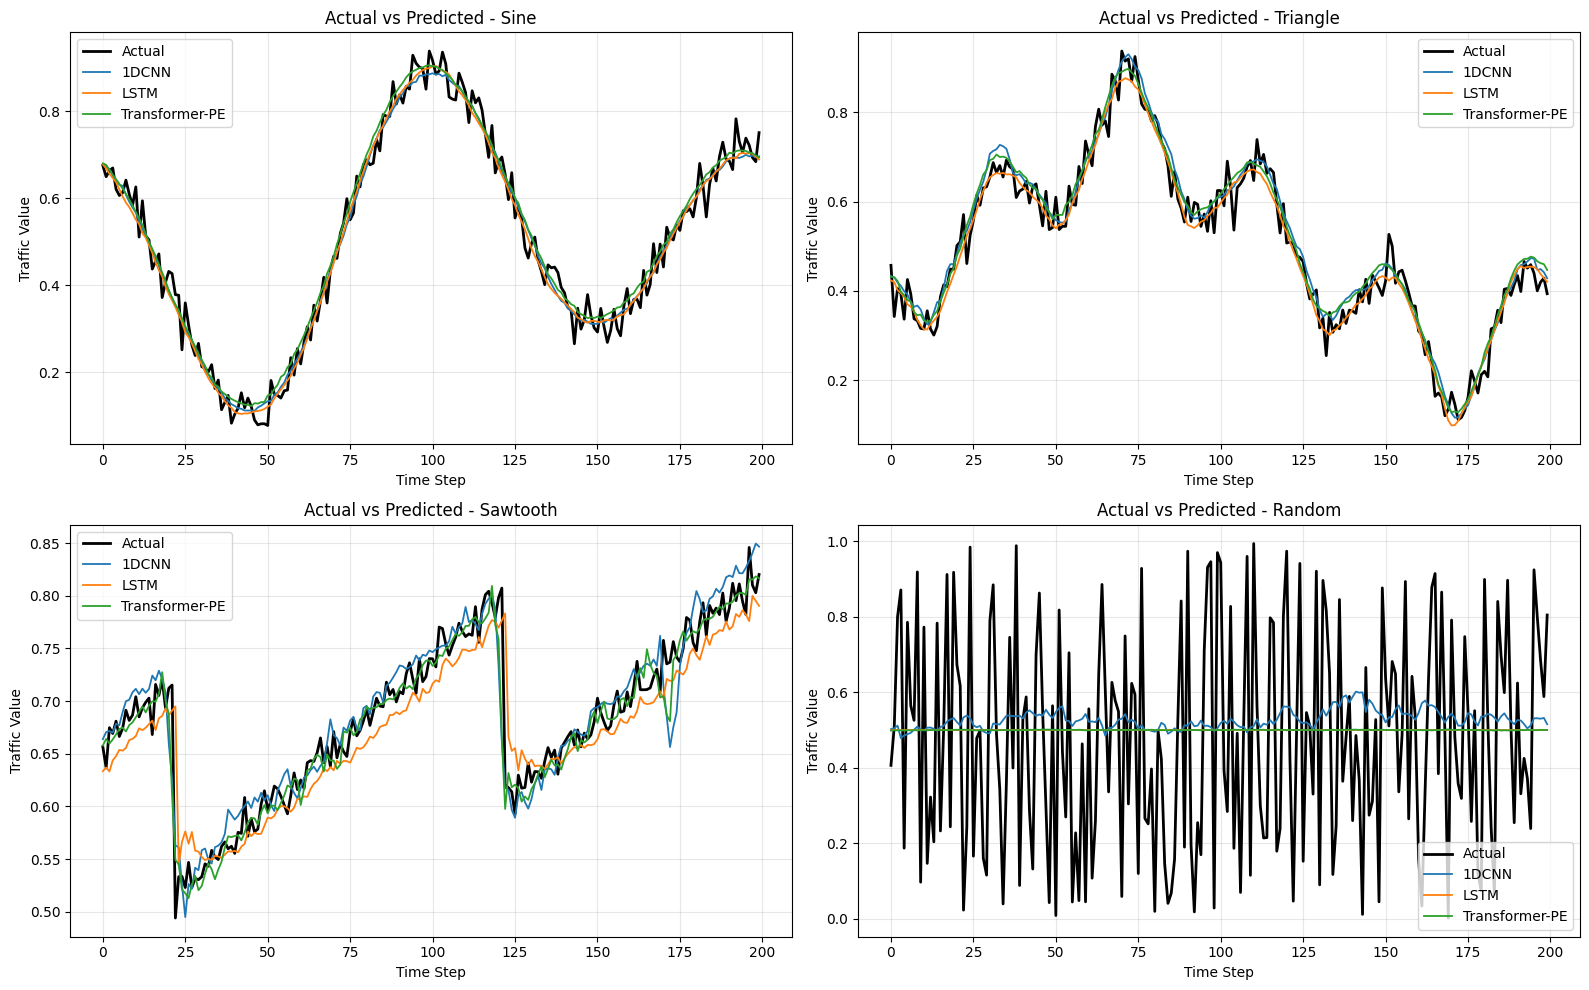

In [88]:
import matplotlib.pyplot as plt
import numpy as np

# Data aktual setiap dataset
actual_datasets = {
    "Sine": y_test,
    "Triangle": y_test_tri,
    "Sawtooth": y_test_saw,
    "Random": y_test_rand
}

# Gabungkan seluruh prediksi model
all_predictions = {
    "1DCNN": predictions_1dcnn,
    "LSTM": predictions_lstm,
    "Transformer-PE": predictions_transformer_pe
}

# Jumlah sampel yang ditampilkan
n_samples = 200

# Buat figure 2x2
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

axes = axes.flatten()

for i, dataset_name in enumerate(actual_datasets):

    ax = axes[i]

    # Data aktual
    actual = actual_datasets[dataset_name][:n_samples, 0]

    ax.plot(
        actual,
        label="Actual",
        color="black",
        linewidth=2
    )

    # Prediksi masing-masing model
    for model_name, predictions_dict in all_predictions.items():

        predicted = predictions_dict[dataset_name][:n_samples, 0]

        ax.plot(
            predicted,
            label=model_name,
            linewidth=1.3
        )

    ax.set_title(f"Actual vs Predicted - {dataset_name}")
    ax.set_xlabel("Time Step")
    ax.set_ylabel("Traffic Value")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [92]:
# Periksa model LSTM
print("MODEL LSTM:")
print(models_lstm.keys())

# Periksa model Transformer-PE
print("\nMODEL TRANSFORMER-PE:")
print(models_transformer_pe.keys())

# Periksa seluruh variabel model yang tersedia
print("\nVARIABEL MODEL:")
for nama, nilai in globals().copy().items():
    if "model" in nama.lower() and hasattr(nilai, "predict"):
        print(nama, "->", type(nilai).__name__)

MODEL LSTM:
dict_keys(['Sine', 'Triangle', 'Sawtooth', 'Random'])

MODEL TRANSFORMER-PE:
dict_keys(['Sine', 'Triangle', 'Sawtooth', 'Random'])

VARIABEL MODEL:
model -> Functional
model_tri -> Sequential
model_saw -> Sequential
model_rand -> Sequential
model_lstm -> Sequential
Model -> type
model_transformer -> Functional


In [93]:
print("Jumlah model LSTM:", len(models_lstm))
print("Jumlah model Transformer-PE:", len(models_transformer_pe))
print("Jumlah prediksi Transformer:", len(predictions_transformer))

Jumlah model LSTM: 4
Jumlah model Transformer-PE: 4
Jumlah prediksi Transformer: 0


In [100]:
print("DAFTAR MODEL DAN ARSITEKTURNYA\n")

for nama, obj in globals().copy().items():

    if isinstance(obj, tf.keras.Model):

        print(f"\nNama variabel: {nama}")
        print("Tipe model:", type(obj).__name__)
        print("Input:", obj.input_shape)
        print("Output:", obj.output_shape)

        layer_types = [
            layer.__class__.__name__
            for layer in obj.layers
        ]

        print("Layers:", layer_types)

DAFTAR MODEL DAN ARSITEKTURNYA


Nama variabel: model
Tipe model: Functional
Input: (None, 128, 1)
Output: (None, 5)
Layers: ['InputLayer', 'Dense', 'PositionalEncoding', 'MultiHeadAttention', 'LayerNormalization', 'Dense', 'Dense', 'LayerNormalization', 'GlobalAveragePooling1D', 'Dense', 'Dense', 'Dense']

Nama variabel: model_tri
Tipe model: Sequential
Input: (None, 128, 1)
Output: (None, 5)
Layers: ['Conv1D', 'MaxPooling1D', 'Flatten', 'Dense', 'Dense', 'Dense']

Nama variabel: model_saw
Tipe model: Sequential
Input: (None, 128, 1)
Output: (None, 5)
Layers: ['Conv1D', 'MaxPooling1D', 'Flatten', 'Dense', 'Dense', 'Dense']

Nama variabel: model_rand
Tipe model: Sequential
Input: (None, 128, 1)
Output: (None, 5)
Layers: ['Conv1D', 'MaxPooling1D', 'Flatten', 'Dense', 'Dense', 'Dense']

Nama variabel: model_lstm
Tipe model: Sequential
Input: (None, 128, 1)
Output: (None, 5)
Layers: ['LSTM', 'Dense', 'Dense', 'Dense']

Nama variabel: transformer_pe_test
Tipe model: Functional
Input: (None

In [101]:
print("MODEL 1DCNN SINE")
print("Variabel model:", model.name)
print("Layer:", [layer.__class__.__name__ for layer in model.layers])

print("\nMODEL 1DCNN TRIANGLE")
print("Layer:", [layer.__class__.__name__ for layer in model_tri.layers])

print("\nMODEL 1DCNN SAWTOOTH")
print("Layer:", [layer.__class__.__name__ for layer in model_saw.layers])

print("\nMODEL 1DCNN RANDOM")
print("Layer:", [layer.__class__.__name__ for layer in model_rand.layers])

MODEL 1DCNN SINE
Variabel model: functional_24
Layer: ['InputLayer', 'Dense', 'PositionalEncoding', 'MultiHeadAttention', 'LayerNormalization', 'Dense', 'Dense', 'LayerNormalization', 'GlobalAveragePooling1D', 'Dense', 'Dense', 'Dense']

MODEL 1DCNN TRIANGLE
Layer: ['Conv1D', 'MaxPooling1D', 'Flatten', 'Dense', 'Dense', 'Dense']

MODEL 1DCNN SAWTOOTH
Layer: ['Conv1D', 'MaxPooling1D', 'Flatten', 'Dense', 'Dense', 'Dense']

MODEL 1DCNN RANDOM
Layer: ['Conv1D', 'MaxPooling1D', 'Flatten', 'Dense', 'Dense', 'Dense']


In [102]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense
from tensorflow.keras.optimizers import Adam

model_1dcnn_sine = Sequential([
    Conv1D(
        filters=16,
        kernel_size=8,
        activation='relu',
        input_shape=(128, 1)
    ),
    MaxPooling1D(pool_size=4),
    Flatten(),
    Dense(32, activation='relu'),
    Dense(8, activation='relu'),
    Dense(5)
])

model_1dcnn_sine.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

model_1dcnn_sine.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 121, 16)        │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 30, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_84 (Dense)                │ (None, 32)             │        15,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_85 (Dense)                │ (None, 8)              │           264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_86 (Dense)                │ (None, 5)              │            45 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,845 (61.89 KB)

 Trainable params: 15,845 (61.89 KB)

 Non-trainable params: 0 (0.00 B)

In [103]:
history_1dcnn_sine = model_1dcnn_sine.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=128,
    verbose=1
)

Epoch 1/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - loss: 0.0769 - mae: 0.1753 - val_loss: 0.0067 - val_mae: 0.0636
Epoch 2/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0038 - mae: 0.0485 - val_loss: 0.0025 - val_mae: 0.0395
Epoch 3/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0020 - mae: 0.0353 - val_loss: 0.0017 - val_mae: 0.0325
Epoch 4/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0016 - mae: 0.0318 - val_loss: 0.0015 - val_mae: 0.0313
Epoch 5/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0015 - mae: 0.0310 - val_loss: 0.0015 - val_mae: 0.0313
Epoch 6/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0015 - mae: 0.0305 - val_loss: 0.0015 - val_mae: 0.0304
Epoch 7/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0014 - mae: 0.0302 - val_loss: 0.0015 - val_mae: 0.0305
Epoch 8/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0014 - mae: 0.0300 - val_loss: 0.0014 - val_mae: 0.0299
Epoch 9/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - lo

In [104]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

pred_sine = model_1dcnn_sine.predict(X_test)

rmse_sine = np.sqrt(mean_squared_error(
    y_test.flatten(),
    pred_sine.flatten()
))

mae_sine = mean_absolute_error(
    y_test.flatten(),
    pred_sine.flatten()
)

print("Hasil Evaluasi 1DCNN Sine")
print("RMSE:", rmse_sine)
print("MAE :", mae_sine)

153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Hasil Evaluasi 1DCNN Sine
RMSE: 0.036953402635671054
MAE : 0.029412738911381534


In [105]:
models_1dcnn = {
    "Sine": model_1dcnn_sine,
    "Triangle": model_tri,
    "Sawtooth": model_saw,
    "Random": model_rand
}

predictions_1dcnn = {
    "Sine": pred_sine,
    "Triangle": predictions_tri,
    "Sawtooth": predictions_saw,
    "Random": predictions_rand
}

print("Model 1DCNN berhasil diperbarui!")

for dataset, modelnya in models_1dcnn.items():
    print(dataset, ":", modelnya.layers[0].__class__.__name__)

Model 1DCNN berhasil diperbarui!
Sine : Conv1D
Triangle : Conv1D
Sawtooth : Conv1D
Random : Conv1D


In [106]:
print("PEMERIKSAAN MODEL LSTM\n")

print("Variabel model_lstm:")
print("Tipe:", type(model_lstm).__name__)
print("Layer:", [layer.__class__.__name__ for layer in model_lstm.layers])

print("\nModel dalam models_lstm:")

for dataset, modelnya in models_lstm.items():
    print(f"\nDataset: {dataset}")
    print("Input:", modelnya.input_shape)
    print("Output:", modelnya.output_shape)
    print("Layer:", [layer.__class__.__name__ for layer in modelnya.layers])

PEMERIKSAAN MODEL LSTM

Variabel model_lstm:
Tipe: Sequential
Layer: ['LSTM', 'Dense', 'Dense', 'Dense']

Model dalam models_lstm:

Dataset: Sine
Input: (None, 128, 1)
Output: (None, 5)
Layer: ['LSTM', 'Dense', 'Dense', 'Dense']

Dataset: Triangle
Input: (None, 128, 1)
Output: (None, 5)
Layer: ['LSTM', 'Dense', 'Dense', 'Dense']

Dataset: Sawtooth
Input: (None, 128, 1)
Output: (None, 5)
Layer: ['LSTM', 'Dense', 'Dense', 'Dense']

Dataset: Random
Input: (None, 128, 1)
Output: (None, 5)
Layer: ['LSTM', 'Dense', 'Dense', 'Dense']


In [107]:
print("PEMERIKSAAN MODEL TRANSFORMER\n")

print("Isi models_transformer:")
print(type(models_transformer))
print("Jumlah model:", len(models_transformer))

for dataset, modelnya in models_transformer.items():
    print(f"\nDataset: {dataset}")
    print("Input:", modelnya.input_shape)
    print("Output:", modelnya.output_shape)
    print("Layer:", [
        layer.__class__.__name__
        for layer in modelnya.layers
    ])

PEMERIKSAAN MODEL TRANSFORMER

Isi models_transformer:
<class 'dict'>
Jumlah model: 0


In [108]:
print("PEMERIKSAAN TRANSFORMER-PE\n")

print("Jumlah model:", len(models_transformer_pe))

for dataset, modelnya in models_transformer_pe.items():
    print(f"\nDataset: {dataset}")
    print("Input:", modelnya.input_shape)
    print("Output:", modelnya.output_shape)
    print("Layer:", [
        layer.__class__.__name__
        for layer in modelnya.layers
    ])

PEMERIKSAAN TRANSFORMER-PE

Jumlah model: 4

Dataset: Sine
Input: (None, 128, 1)
Output: (None, 5)
Layer: ['InputLayer', 'Dense', 'PositionalEncoding', 'MultiHeadAttention', 'LayerNormalization', 'Dense', 'Dense', 'LayerNormalization', 'GlobalAveragePooling1D', 'Dense', 'Dense', 'Dense']

Dataset: Triangle
Input: (None, 128, 1)
Output: (None, 5)
Layer: ['InputLayer', 'Dense', 'PositionalEncoding', 'MultiHeadAttention', 'LayerNormalization', 'Dense', 'Dense', 'LayerNormalization', 'GlobalAveragePooling1D', 'Dense', 'Dense', 'Dense']

Dataset: Sawtooth
Input: (None, 128, 1)
Output: (None, 5)
Layer: ['InputLayer', 'Dense', 'PositionalEncoding', 'MultiHeadAttention', 'LayerNormalization', 'Dense', 'Dense', 'LayerNormalization', 'GlobalAveragePooling1D', 'Dense', 'Dense', 'Dense']

Dataset: Random
Input: (None, 128, 1)
Output: (None, 5)
Layer: ['InputLayer', 'Dense', 'PositionalEncoding', 'MultiHeadAttention', 'LayerNormalization', 'Dense', 'Dense', 'LayerNormalization', 'GlobalAveragePooli

In [109]:
import time
import numpy as np

datasets_transformer = {
    "Sine": (X_train, y_train, X_val, y_val),
    "Triangle": (X_train_tri, y_train_tri, X_val_tri, y_val_tri),
    "Sawtooth": (X_train_saw, y_train_saw, X_val_saw, y_val_saw),
    "Random": (X_train_rand, y_train_rand, X_val_rand, y_val_rand)
}

models_transformer = {}
histories_transformer = {}
training_times_transformer = {}

for nama, (Xtr, ytr, Xv, yv) in datasets_transformer.items():

    print(f"\nMelatih Transformer: {nama}")

    model_transformer_baru = create_transformer_model()

    start_time = time.perf_counter()

    history = model_transformer_baru.fit(
        Xtr,
        ytr,
        validation_data=(Xv, yv),
        epochs=10,
        batch_size=128,
        verbose=1
    )

    end_time = time.perf_counter()

    models_transformer[nama] = model_transformer_baru
    histories_transformer[nama] = history
    training_times_transformer[nama] = end_time - start_time

print("\nSELESAI MELATIH SEMUA TRANSFORMER")

for nama, waktu in training_times_transformer.items():
    print(f"{nama}: {waktu:.4f} detik")


Melatih Transformer: Sine
Epoch 1/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 12s 21ms/step - loss: 0.0385 - mae: 0.1251 - val_loss: 0.0015 - val_mae: 0.0314
Epoch 2/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0013 - mae: 0.0285 - val_loss: 0.0012 - val_mae: 0.0272
Epoch 3/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0012 - mae: 0.0274 - val_loss: 0.0011 - val_mae: 0.0272
Epoch 4/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0012 - mae: 0.0277 - val_loss: 0.0013 - val_mae: 0.0291
Epoch 5/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0012 - mae: 0.0276 - val_loss: 0.0012 - val_mae: 0.0279
Epoch 6/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0012 - mae: 0.0276 - val_loss: 0.0011 - val_mae: 0.0270
Epoch 7/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0012 - mae: 0.0275 - val_loss: 0.0018 - val_mae: 0.0343
Epoch 8/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0012 - mae: 0.0276 - val_loss: 0.0012 - val_mae: 0.0278
Epoch 9/10
316/316 ━━━━━━━━

In [110]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np
import pandas as pd

datasets_test = {
    "Sine": (X_test, y_test),
    "Triangle": (X_test_tri, y_test_tri),
    "Sawtooth": (X_test_saw, y_test_saw),
    "Random": (X_test_rand, y_test_rand)
}

hasil_transformer_baru = []
predictions_transformer = {}

for nama, (Xte, yte) in datasets_test.items():

    modelnya = models_transformer[nama]

    prediksi = modelnya.predict(Xte, verbose=0)

    rmse = np.sqrt(mean_squared_error(
        yte.flatten(),
        prediksi.flatten()
    ))

    mae = mean_absolute_error(
        yte.flatten(),
        prediksi.flatten()
    )

    predictions_transformer[nama] = prediksi

    hasil_transformer_baru.append({
        "Dataset": nama,
        "Model": "Transformer",
        "RMSE": rmse,
        "MAE": mae
    })

hasil_transformer_baru_df = pd.DataFrame(hasil_transformer_baru)

print("HASIL EVALUASI TRANSFORMER")
display(hasil_transformer_baru_df)

HASIL EVALUASI TRANSFORMER


,Dataset,Model,RMSE,MAE
0,Sine,Transformer,0.034064,0.027140
1,Triangle,Transformer,0.033057,0.026541
2,Sawtooth,Transformer,0.043143,0.020880
3,Random,Transformer,0.287875,0.248298


In [111]:
print("Jumlah history Transformer-PE:",
      len(histories_transformer_pe))

for dataset, history in histories_transformer_pe.items():
    print(dataset, ":", len(history.history["loss"]), "epoch")

Jumlah history Transformer-PE: 4
Sine : 10 epoch
Triangle : 10 epoch
Sawtooth : 10 epoch
Random : 10 epoch


In [112]:
print("Variabel training time Transformer-PE tersedia:")

print("training_times_transformer_pe" in globals())

if "training_times_transformer_pe" in globals():
    print(training_times_transformer_pe)

Variabel training time Transformer-PE tersedia:
False


In [113]:
print("Fungsi pembuat Transformer yang tersedia:\n")

for nama in globals():
    if "transformer" in nama.lower() and callable(globals()[nama]):
        print(nama)

Fungsi pembuat Transformer yang tersedia:

create_transformer_model
transformer_pe_test
model_transformer
model_transformer_baru


In [114]:
import inspect

print(inspect.getsource(create_transformer_model))

def create_transformer_model():

    inputs = Input(shape=(128, 1))

    # Input Embedding
    x = Dense(32)(inputs)

    # Positional Encoding
    x = PositionalEncoding(
        sequence_length=128,
        embedding_dim=32
    )(x)

    # Multi-Head Attention
    attention = MultiHeadAttention(
        num_heads=4,
        key_dim=8
    )(x, x)

    # Residual Connection + Layer Normalization
    x = LayerNormalization(epsilon=1e-6)(x + attention)

    # Feed Forward Network
    ff = Dense(64, activation="relu")(x)
    ff = Dense(32)(ff)

    # Residual Connection + Layer Normalization
    x = LayerNormalization(epsilon=1e-6)(x + ff)

    # Global Average Pooling
    x = GlobalAveragePooling1D()(x)

    # Fully Connected Layers
    x = Dense(32, activation="relu")(x)
    x = Dense(8, activation="relu")(x)

    # Output prediksi 5 langkah
    outputs = Dense(5, activation="linear")(x)

    model = Model(inputs, outputs)

    model.compile(
        optimizer=Adam(learning_rate=0.001),

In [115]:

import time

training_times_transformer_pe = {}
models_transformer_pe_time = {}

datasets_pe = {
    "Sine": (X_train, y_train, X_val, y_val),
    "Triangle": (X_train_tri, y_train_tri, X_val_tri, y_val_tri),
    "Sawtooth": (X_train_saw, y_train_saw, X_val_saw, y_val_saw),
    "Random": (X_train_rand, y_train_rand, X_val_rand, y_val_rand)
}

for nama, (Xtr, ytr, Xv, yv) in datasets_pe.items():

    print(f"\nTraining Transformer-PE {nama}")

    model_baru = create_transformer_model()

    start_time = time.perf_counter()

    model_baru.fit(
        Xtr, ytr,
        validation_data=(Xv, yv),
        epochs=10,
        batch_size=128,
        verbose=1
    )

    end_time = time.perf_counter()

    training_times_transformer_pe[nama] = end_time - start_time
    models_transformer_pe_time[nama] = model_baru

print("\nHASIL TRAINING TIME TRANSFORMER-PE")

for nama, waktu in training_times_transformer_pe.items():
    print(f"{nama}: {waktu:.4f} detik")

print(
    "\nRata-rata:",
    sum(training_times_transformer_pe.values()) / 4,
    "detik"
)



Training Transformer-PE Sine
Epoch 1/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - loss: 0.0529 - mae: 0.1412 - val_loss: 0.0036 - val_mae: 0.0457
Epoch 2/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0028 - mae: 0.0410 - val_loss: 0.0024 - val_mae: 0.0380
Epoch 3/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0021 - mae: 0.0358 - val_loss: 0.0018 - val_mae: 0.0341
Epoch 4/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0017 - mae: 0.0329 - val_loss: 0.0016 - val_mae: 0.0321
Epoch 5/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0015 - mae: 0.0314 - val_loss: 0.0017 - val_mae: 0.0331
Epoch 6/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0015 - mae: 0.0311 - val_loss: 0.0015 - val_mae: 0.0306
Epoch 7/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0015 - mae: 0.0310 - val_loss: 0.0015 - val_mae: 0.0308
Epoch 8/10
316/316 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0015 - mae: 0.0308 - val_loss: 0.0015 - val_mae: 0.0309
Epoch 9/10
316/316 ━━━━━

In [116]:
print("=== PEMERIKSAAN HISTORY TRAINING ===")

for nama_variabel in [
    "histories_lstm",
    "histories_1dcnn",
    "history_1dcnn_sine",
    "histories_transformer",
    "histories_transformer_pe"
]:
    print(
        nama_variabel,
        ":",
        nama_variabel in globals()
    )

=== PEMERIKSAAN HISTORY TRAINING ===
histories_lstm : False
histories_1dcnn : False
history_1dcnn_sine : True
histories_transformer : True
histories_transformer_pe : True


In [117]:
print("=== VARIABEL WAKTU TRAINING ===")

for nama in globals():
    if "training_time" in nama.lower() or "waktu_training" in nama.lower():
        print(nama, ":", type(globals()[nama]).__name__)

=== VARIABEL WAKTU TRAINING ===
training_times_transformer : dict
training_times_transformer_pe : dict


In [118]:
print("=== VARIABEL HISTORY YANG TERSEDIA ===")

for nama in globals():
    if "history" in nama.lower():
        print(nama)

=== VARIABEL HISTORY YANG TERSEDIA ===
history
history_tri
history_saw
history_rand
history_lstm
history_1dcnn_sine


In [120]:
print("=== MODEL LSTM ===")

for nama, model in models_lstm.items():
    print(f"\nDataset: {nama}")
    print("Input:", model.input_shape)
    print("Output:", model.output_shape)

print("\n=== HISTORY LSTM ===")
print("Epoch:", len(history_lstm.history["loss"]))
print("Training loss terakhir:", history_lstm.history["loss"][-1])
print("Validation loss terakhir:", history_lstm.history["val_loss"][-1])

=== MODEL LSTM ===

Dataset: Sine
Input: (None, 128, 1)
Output: (None, 5)

Dataset: Triangle
Input: (None, 128, 1)
Output: (None, 5)

Dataset: Sawtooth
Input: (None, 128, 1)
Output: (None, 5)

Dataset: Random
Input: (None, 128, 1)
Output: (None, 5)

=== HISTORY LSTM ===
Epoch: 10
Training loss terakhir: 0.0829516351222992
Validation loss terakhir: 0.08332689106464386


In [121]:
print("=== VARIABEL TERKAIT LSTM ===")

for nama in globals():
    if "lstm" in nama.lower():
        print(nama, ":", type(globals()[nama]).__name__)

=== VARIABEL TERKAIT LSTM ===
LSTM : type
create_lstm_model : function
datasets_lstm : list
hasil_lstm : list
models_lstm : dict
predictions_lstm : dict
model_lstm : Sequential
history_lstm : History
hasil_lstm_df : DataFrame


In [122]:
print("\n=== VARIABEL TERKAIT 1DCNN ===")

for nama in globals():
    if "cnn" in nama.lower() or "1dcnn" in nama.lower():
        print(nama, ":", type(globals()[nama]).__name__)


=== VARIABEL TERKAIT 1DCNN ===
hasil_1dcnn : DataFrame
predictions_1dcnn : dict
model_1dcnn_sine : Sequential
history_1dcnn_sine : History
models_1dcnn : dict


In [123]:
print("=== HASIL LSTM ===")
display(hasil_lstm_df)

print("\n=== HASIL 1DCNN ===")
display(hasil_1dcnn)

=== HASIL LSTM ===


,Dataset,Model,RMSE,MAE
0,Sine,LSTM,0.035065,0.028013
1,Triangle,LSTM,0.035031,0.027980
2,Sawtooth,LSTM,0.058212,0.028877
3,Random,LSTM,0.286894,0.247615



=== HASIL 1DCNN ===


,Dataset,Model,RMSE,MAE
0,Sine,1DCNN,0.034900,0.027878
1,Triangle,1DCNN,0.033630,0.026951
2,Sawtooth,1DCNN,0.041710,0.020635
3,Random,1DCNN,0.288404,0.248539


In [124]:
print("=== DATASETS LSTM ===")
print(datasets_lstm)

=== DATASETS LSTM ===
[('Sine', array([[[0.5702],
        [0.4884],
        [0.5232],
        ...,
        [0.715 ],
        [0.6685],
        [0.679 ]],

       [[0.4884],
        [0.5232],
        [0.5057],
        ...,
        [0.6685],
        [0.679 ],
        [0.6509]],

       [[0.5232],
        [0.5057],
        [0.6119],
        ...,
        [0.679 ],
        [0.6509],
        [0.7156]],

       ...,

       [[0.1554],
        [0.102 ],
        [0.1266],
        ...,
        [0.3796],
        [0.3309],
        [0.3957]],

       [[0.102 ],
        [0.1266],
        [0.0881],
        ...,
        [0.3309],
        [0.3957],
        [0.3963]],

       [[0.1266],
        [0.0881],
        [0.1517],
        ...,
        [0.3957],
        [0.3963],
        [0.4206]]], shape=(40367, 128, 1)), array([[0.6509, 0.7156, 0.6761, 0.6494, 0.6334],
       [0.7156, 0.6761, 0.6494, 0.6334, 0.6576],
       [0.6761, 0.6494, 0.6334, 0.6576, 0.5971],
       ...,
       [0.3963, 0.4206, 0.5085, 0.

In [125]:

import time
import pandas as pd
import numpy as np

models_all = {
    "Sine": {
        "1DCNN": models_1dcnn["Sine"],
        "LSTM": models_lstm["Sine"],
        "Transformer": models_transformer["Sine"],
        "Transformer-PE": models_transformer_pe["Sine"]
    },
    "Triangle": {
        "1DCNN": models_1dcnn["Triangle"],
        "LSTM": models_lstm["Triangle"],
        "Transformer": models_transformer["Triangle"],
        "Transformer-PE": models_transformer_pe["Triangle"]
    },
    "Sawtooth": {
        "1DCNN": models_1dcnn["Sawtooth"],
        "LSTM": models_lstm["Sawtooth"],
        "Transformer": models_transformer["Sawtooth"],
        "Transformer-PE": models_transformer_pe["Sawtooth"]
    },
    "Random": {
        "1DCNN": models_1dcnn["Random"],
        "LSTM": models_lstm["Random"],
        "Transformer": models_transformer["Random"],
        "Transformer-PE": models_transformer_pe["Random"]
    }
}

datasets_test = {
    "Sine": X_test,
    "Triangle": X_test_tri,
    "Sawtooth": X_test_saw,
    "Random": X_test_rand
}

hasil_inference = []

for dataset, model_dict in models_all.items():

    Xte = datasets_test[dataset]

    for nama_model, model in model_dict.items():

        # Warm-up
        model.predict(Xte[:5], verbose=0)

        # Pengukuran 20 kali
        waktu_mulai = time.perf_counter()

        for _ in range(20):
            model.predict(Xte, batch_size=128, verbose=0)

        waktu_total = (time.perf_counter() - waktu_mulai) / 20

        jumlah_sampel = len(Xte)

        hasil_inference.append({
            "Dataset": dataset,
            "Model": nama_model,
            "Inference Time (s)": waktu_total,
            "Time per Sample (ms)": (
                waktu_total / jumlah_sampel * 1000
            ),
            "Throughput (samples/s)": (
                jumlah_sampel / waktu_total
            )
        })

hasil_inference_df = pd.DataFrame(hasil_inference)

display(hasil_inference_df.round(6))


,Dataset,Model,Inference Time (s),Time per Sample (ms),Throughput (samples/s)
0,Sine,1DCNN,0.273147,0.056122,17818.276901
1,Sine,LSTM,0.235933,0.048476,20628.747853
2,Sine,Transformer,0.246651,0.050678,19732.311195
3,Sine,Transformer-PE,0.228503,0.046949,21299.520829
4,Triangle,1DCNN,0.217199,0.044627,22407.997897
5,Triangle,LSTM,0.240882,0.049493,20204.931085
6,Triangle,Transformer,0.259935,0.053408,18723.886543
7,Triangle,Transformer-PE,0.233480,0.047972,20845.462969
8,Sawtooth,1DCNN,0.159209,0.032712,30569.884039
9,Sawtooth,LSTM,0.283316,0.058212,17178.686061


In [126]:

import time
import pandas as pd
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv1D, MaxPooling1D, Flatten, Dense
from tensorflow.keras.optimizers import Adam

# Dataset training dan validasi
datasets_training = {
    "Sine": (X_train, y_train, X_val, y_val),
    "Triangle": (X_train_tri, y_train_tri, X_val_tri, y_val_tri),
    "Sawtooth": (X_train_saw, y_train_saw, X_val_saw, y_val_saw),
    "Random": (X_train_rand, y_train_rand, X_val_rand, y_val_rand)
}

# Factory model 1DCNN
def create_1dcnn_model():
    model = Sequential([
        Conv1D(16, 8, activation='relu', input_shape=(128, 1)),
        MaxPooling1D(pool_size=4),
        Flatten(),
        Dense(32, activation='relu'),
        Dense(8, activation='relu'),
        Dense(5)
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss='mse',
        metrics=['mae']
    )
    return model

# Pengukuran training time 1DCNN
training_times_1dcnn = {}
models_1dcnn_time = {}

for nama, (Xtr, ytr, Xv, yv) in datasets_training.items():
    model_baru = create_1dcnn_model()

    start = time.perf_counter()

    model_baru.fit(
        Xtr, ytr,
        validation_data=(Xv, yv),
        epochs=10,
        batch_size=128,
        verbose=0
    )

    end = time.perf_counter()

    training_times_1dcnn[nama] = end - start
    models_1dcnn_time[nama] = model_baru

# Tampilkan hasil
hasil_training_1dcnn = pd.DataFrame([
    {"Dataset": nama, "Model": "1DCNN", "Training Time (s)": waktu}
    for nama, waktu in training_times_1dcnn.items()
])

display(hasil_training_1dcnn.round(4))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


,Dataset,Model,Training Time (s)
0,Sine,1DCNN,17.0725
1,Triangle,1DCNN,16.1566
2,Sawtooth,1DCNN,16.2387
3,Random,1DCNN,17.8037


In [127]:

training_times_lstm = {}
models_lstm_time = {}

for nama, (Xtr, ytr, Xv, yv) in datasets_training.items():

    model_baru = create_lstm_model()

    start = time.perf_counter()

    model_baru.fit(
        Xtr, ytr,
        validation_data=(Xv, yv),
        epochs=10,
        batch_size=128,
        verbose=0
    )

    end = time.perf_counter()

    training_times_lstm[nama] = end - start
    models_lstm_time[nama] = model_baru

hasil_training_lstm = pd.DataFrame([
    {
        "Dataset": nama,
        "Model": "LSTM",
        "Training Time (s)": waktu
    }
    for nama, waktu in training_times_lstm.items()
])

display(hasil_training_lstm.round(4))


,Dataset,Model,Training Time (s)
0,Sine,LSTM,35.0049
1,Triangle,LSTM,32.5513
2,Sawtooth,LSTM,31.1910
3,Random,LSTM,32.5279


In [128]:

hasil_training_semua = []

for nama in datasets_training.keys():
    hasil_training_semua.extend([
        {
            "Dataset": nama,
            "Model": "1DCNN",
            "Training Time (s)": training_times_1dcnn[nama]
        },
        {
            "Dataset": nama,
            "Model": "LSTM",
            "Training Time (s)": training_times_lstm[nama]
        },
        {
            "Dataset": nama,
            "Model": "Transformer",
            "Training Time (s)": training_times_transformer[nama]
        },
        {
            "Dataset": nama,
            "Model": "Transformer-PE",
            "Training Time (s)": training_times_transformer_pe[nama]
        }
    ])

hasil_training_df = pd.DataFrame(hasil_training_semua)

display(hasil_training_df.round(4))


,Dataset,Model,Training Time (s)
0,Sine,1DCNN,17.0725
1,Sine,LSTM,35.0049
2,Sine,Transformer,31.2551
3,Sine,Transformer-PE,31.9691
4,Triangle,1DCNN,16.1566
5,Triangle,LSTM,32.5513
6,Triangle,Transformer,32.8610
7,Triangle,Transformer-PE,32.4899
8,Sawtooth,1DCNN,16.2387
9,Sawtooth,LSTM,31.1910


In [129]:

import numpy as np
import pandas as pd

# Data target setiap dataset
targets_test = {
    "Sine": y_test,
    "Triangle": y_test_tri,
    "Sawtooth": y_test_saw,
    "Random": y_test_rand
}

# Evaluasi RMSE dan MAE dari model yang digunakan
hasil_evaluasi = []

for dataset, model_dict in models_all.items():

    Xte = datasets_test[dataset]
    yte = targets_test[dataset]

    for nama_model, model in model_dict.items():

        pred = model.predict(Xte, batch_size=128, verbose=0)

        rmse = np.sqrt(np.mean((yte - pred) ** 2))
        mae = np.mean(np.abs(yte - pred))

        hasil_evaluasi.append({
            "Dataset": dataset,
            "Model": nama_model,
            "RMSE": rmse,
            "MAE": mae
        })

hasil_evaluasi_df = pd.DataFrame(hasil_evaluasi)

# Gabungkan dengan Training Time
hasil_final_df = hasil_evaluasi_df.merge(
    hasil_training_df,
    on=["Dataset", "Model"]
)

# Gabungkan dengan Inference Time dan Throughput
hasil_final_df = hasil_final_df.merge(
    hasil_inference_df,
    on=["Dataset", "Model"]
)

# Urutan kolom
hasil_final_df = hasil_final_df[
    [
        "Dataset",
        "Model",
        "RMSE",
        "MAE",
        "Training Time (s)",
        "Inference Time (s)",
        "Time per Sample (ms)",
        "Throughput (samples/s)"
    ]
]

display(hasil_final_df.round(6))

# Simpan hasil final
hasil_final_df.to_csv(
    "hasil_evaluasi_final.csv",
    index=False
)

print("Berhasil! File hasil_evaluasi_final.csv sudah disimpan.")


,Dataset,Model,RMSE,MAE,Training Time (s),Inference Time (s),Time per Sample (ms),Throughput (samples/s)
0,Sine,1DCNN,0.036953,0.029413,17.072475,0.273147,0.056122,17818.276901
1,Sine,LSTM,0.035065,0.028013,35.004926,0.235933,0.048476,20628.747853
2,Sine,Transformer,0.034064,0.027140,31.255077,0.246651,0.050678,19732.311195
3,Sine,Transformer-PE,0.036226,0.028960,31.969068,0.228503,0.046949,21299.520829
4,Triangle,1DCNN,0.033630,0.026951,16.156601,0.217199,0.044627,22407.997897
5,Triangle,LSTM,0.035031,0.027980,32.551335,0.240882,0.049493,20204.931085
6,Triangle,Transformer,0.033057,0.026541,32.861030,0.259935,0.053408,18723.886543
7,Triangle,Transformer-PE,0.038040,0.030462,32.489907,0.233480,0.047972,20845.462969
8,Sawtooth,1DCNN,0.041710,0.020635,16.238671,0.159209,0.032712,30569.884039
9,Sawtooth,LSTM,0.058212,0.028877,31.191028,0.283316,0.058212,17178.686061


Berhasil! File hasil_evaluasi_final.csv sudah disimpan.


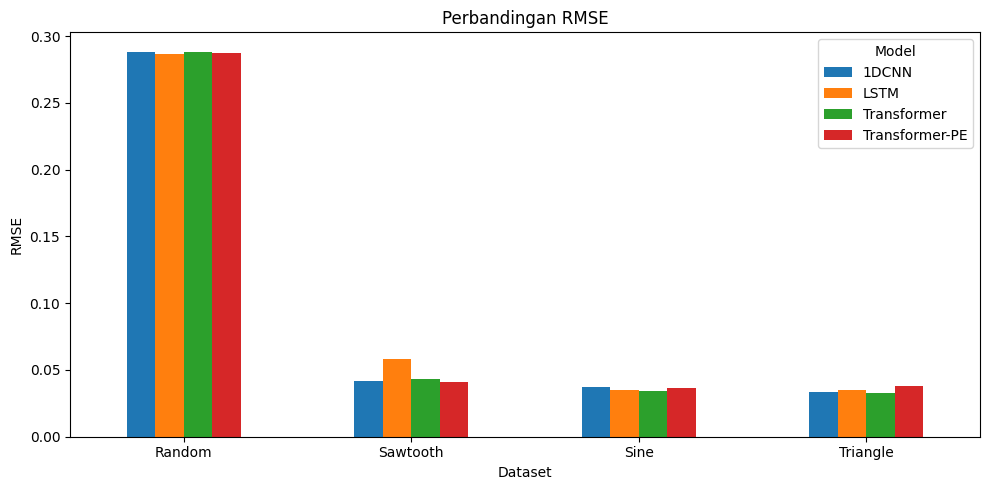

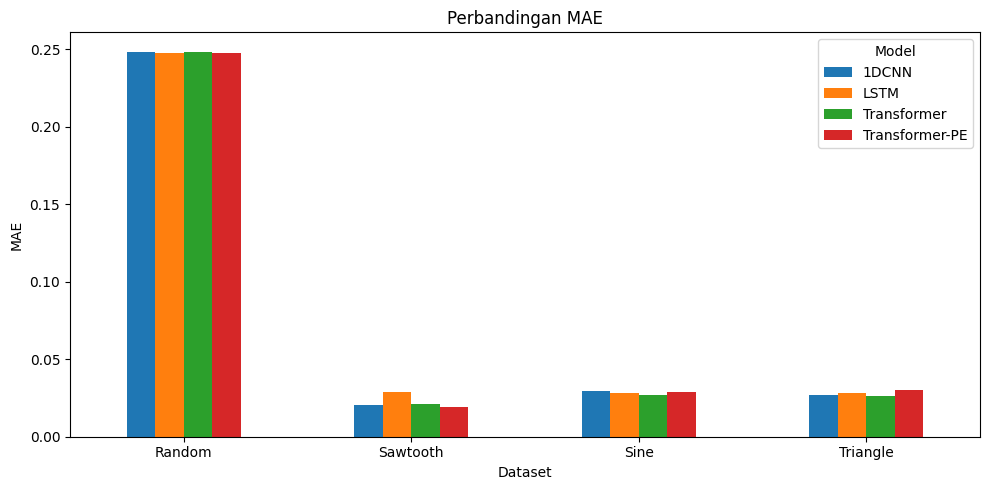

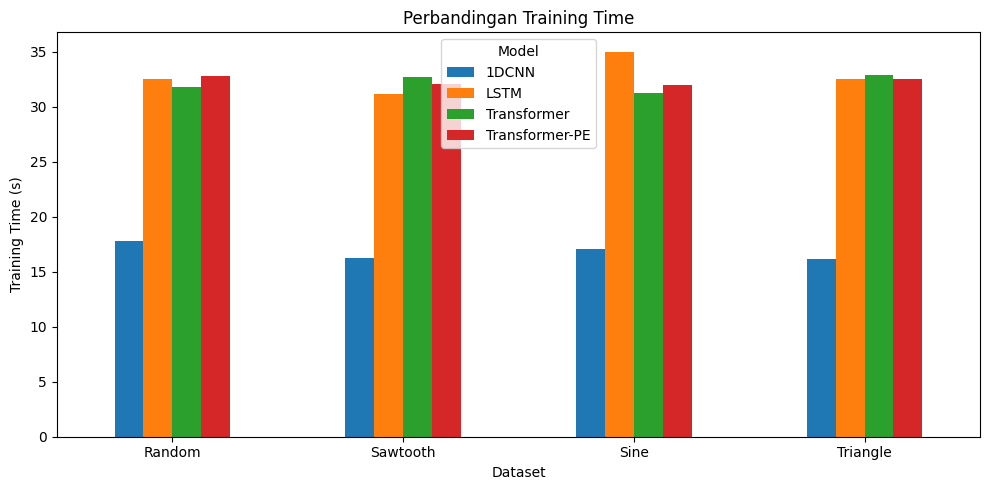

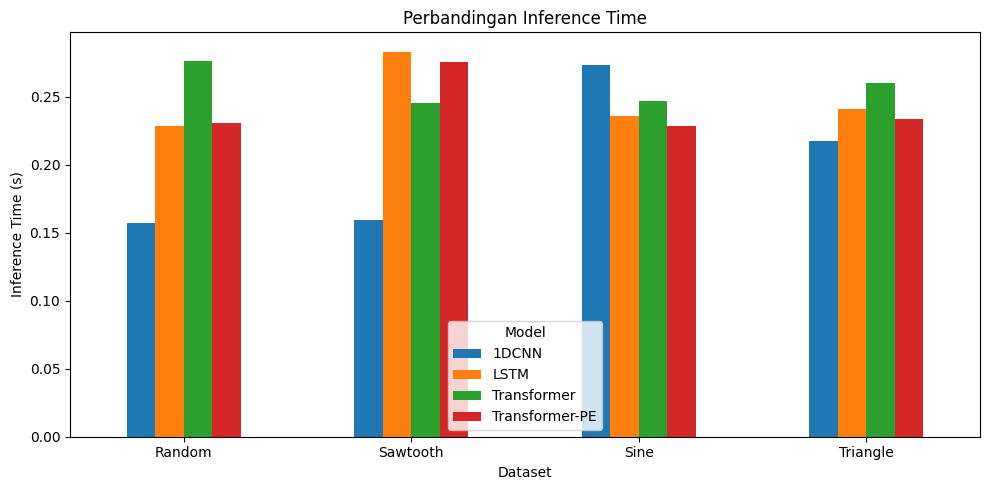

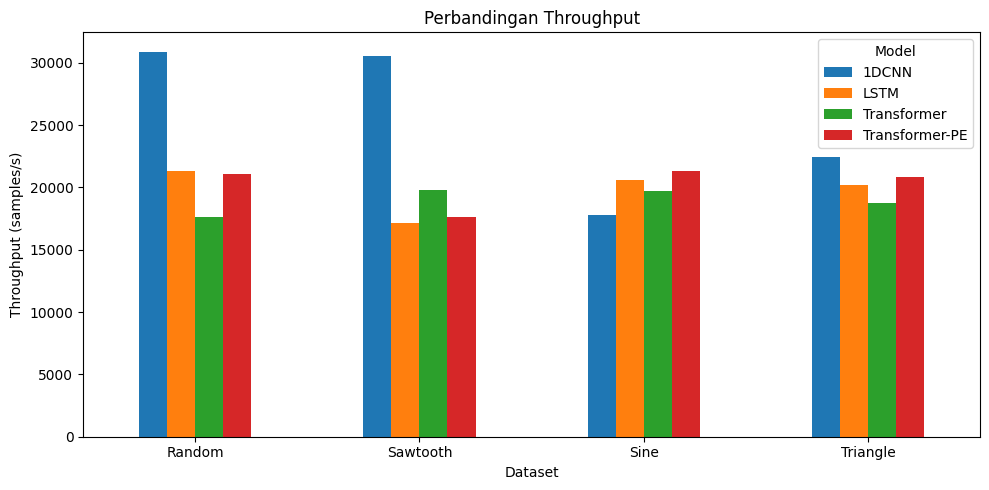

Berhasil membuat dan menyimpan 5 grafik!


In [130]:

import matplotlib.pyplot as plt
import os

# Buat folder penyimpanan grafik
os.makedirs("grafik_eksperimen", exist_ok=True)

metrik_grafik = [
    ("RMSE", "Perbandingan RMSE"),
    ("MAE", "Perbandingan MAE"),
    ("Training Time (s)", "Perbandingan Training Time"),
    ("Inference Time (s)", "Perbandingan Inference Time"),
    ("Throughput (samples/s)", "Perbandingan Throughput")
]

for kolom, judul in metrik_grafik:

    pivot = hasil_final_df.pivot(
        index="Dataset",
        columns="Model",
        values=kolom
    )

    fig, ax = plt.subplots(figsize=(10, 5))

    pivot.plot(kind="bar", ax=ax)

    ax.set_title(judul)
    ax.set_xlabel("Dataset")
    ax.set_ylabel(kolom)
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="Model")

    fig.tight_layout()

    nama_file = (
        kolom.lower()
        .replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("/", "_")
    )

    fig.savefig(
        f"grafik_eksperimen/grafik_{nama_file}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

print("Berhasil membuat dan menyimpan 5 grafik!")


In [131]:

import sys
import platform
import subprocess
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib
import psutil

print("===== SOFTWARE ENVIRONMENT =====")
print("Python       :", sys.version.split()[0])
print("TensorFlow   :", tf.__version__)
print("NumPy        :", np.__version__)
print("Pandas       :", pd.__version__)
print("Matplotlib   :", matplotlib.__version__)
print("Operating OS :", platform.platform())

try:
    import sklearn
    print("Scikit-learn :", sklearn.__version__)
except ImportError:
    print("Scikit-learn : Not installed")

print("\n===== HARDWARE SPECIFICATION =====")
print("CPU          :", platform.processor())
print("CPU Cores    :", psutil.cpu_count(logical=False))
print("Logical CPUs :", psutil.cpu_count(logical=True))
print("System RAM   :", round(psutil.virtual_memory().total / (1024**3), 2), "GB")

print("\n===== GPU INFORMATION =====")
gpu_devices = tf.config.list_physical_devices("GPU")
print("GPU Devices  :", gpu_devices)

for gpu in gpu_devices:
    print("GPU Details  :", tf.config.experimental.get_device_details(gpu))

print("\n===== NVIDIA GPU DETAILS =====")
try:
    result = subprocess.run(
        ["nvidia-smi"],
        capture_output=True,
        text=True
    )
    print(result.stdout)
except Exception as e:
    print("GPU information unavailable:", e)

print("\n===== CUDA BUILD INFORMATION =====")
print(tf.sysconfig.get_build_info())


===== SOFTWARE ENVIRONMENT =====
Python       : 3.13.16
TensorFlow   : 2.21.0
NumPy        : 2.4.6
Pandas       : 2.2.3
Matplotlib   : 3.10.0
Operating OS : Linux-6.6.159+-x86_64-with-glibc2.39
Scikit-learn : 1.6.1

===== HARDWARE SPECIFICATION =====
CPU          : x86_64
CPU Cores    : 1
Logical CPUs : 2
System RAM   : 12.67 GB

===== GPU INFORMATION =====
GPU Devices  : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU Details  : {'compute_capability': (7, 5), 'device_name': 'Tesla T4'}

===== NVIDIA GPU DETAILS =====
Thu Nov 26 07:38:24 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |          

In [132]:

print("===== DATASET SPLIT VERIFICATION =====")

datasets_check = {
    "Sine": (X_train, X_val, X_test),
    "Triangle": (X_train_tri, X_val_tri, X_test_tri),
    "Sawtooth": (X_train_saw, X_val_saw, X_test_saw),
    "Random": (X_train_rand, X_val_rand, X_test_rand)
}

for nama, (Xtr, Xv, Xte) in datasets_check.items():

    total = len(Xtr) + len(Xv) + len(Xte)

    print(f"\nDataset: {nama}")
    print("Train      :", len(Xtr), f"({len(Xtr)/total*100:.2f}%)")
    print("Validation :", len(Xv), f"({len(Xv)/total*100:.2f}%)")
    print("Test       :", len(Xte), f"({len(Xte)/total*100:.2f}%)")
    print("Total      :", total)


===== DATASET SPLIT VERIFICATION =====

Dataset: Sine
Train      : 40367 (81.38%)
Validation : 4367 (8.80%)
Test       : 4867 (9.81%)
Total      : 49601

Dataset: Triangle
Train      : 40367 (81.38%)
Validation : 4367 (8.80%)
Test       : 4867 (9.81%)
Total      : 49601

Dataset: Sawtooth
Train      : 40367 (81.38%)
Validation : 4367 (8.80%)
Test       : 4867 (9.81%)
Total      : 49601

Dataset: Random
Train      : 40367 (81.38%)
Validation : 4367 (8.80%)
Test       : 4867 (9.81%)
Total      : 49601


In [133]:

import pandas as pd
import numpy as np

# ==========================================
# SANITY CHECK - PAPER 2
# ==========================================

# Nilai RMSE referensi dari catatan Paper 2.
# Nilai ini perlu dipastikan kembali dari tabel paper asli.
rmse_referensi = 0.0338

# Ambil hasil evaluasi eksperimen
df_sanity = hasil_final_df.copy()

# Pastikan kolom metrik tersedia
kolom_wajib = ["Dataset", "Model", "RMSE", "MAE"]

for kolom in kolom_wajib:
    if kolom not in df_sanity.columns:
        raise ValueError(f"Kolom {kolom} tidak ditemukan!")

# ==========================================
# 1. VERIFIKASI DATA HASIL EKSPERIMEN
# ==========================================

print("===== SANITY CHECK: DATA VALIDATION =====")

print("Jumlah baris:", len(df_sanity))
print("Dataset:", df_sanity["Dataset"].unique())
print("Model:", df_sanity["Model"].unique())

print("\nMissing values:")
print(df_sanity[kolom_wajib].isnull().sum())

print("\nCek nilai RMSE dan MAE:")
print("RMSE valid:", (df_sanity["RMSE"] >= 0).all())
print("MAE valid :", (df_sanity["MAE"] >= 0).all())

# ==========================================
# 2. PERBANDINGAN DENGAN REFERENSI
# ==========================================

# Ambil hasil 1DCNN pada dataset Sine
hasil_replikasi = df_sanity[
    (df_sanity["Dataset"] == "Sine") &
    (df_sanity["Model"] == "1DCNN")
]["RMSE"].iloc[0]

selisih = abs(hasil_replikasi - rmse_referensi)

persentase_selisih = (
    selisih / rmse_referensi
) * 100

perbandingan = pd.DataFrame({
    "Keterangan": [
        "RMSE Referensi Paper",
        "RMSE Hasil Eksperimen",
        "Selisih Absolut",
        "Selisih Persentase"
    ],
    "Nilai": [
        rmse_referensi,
        hasil_replikasi,
        selisih,
        persentase_selisih
    ]
})

print("\n===== COMPARISON WITH PAPER 2 =====")
display(perbandingan)

# ==========================================
# 3. STATUS SANITY CHECK
# ==========================================

print("\n===== SANITY CHECK RESULT =====")

if persentase_selisih <= 5:
    print("Hasil RMSE relatif dekat dengan nilai referensi.")
elif persentase_selisih <= 10:
    print("Hasil RMSE memiliki perbedaan moderat.")
else:
    print("Hasil RMSE memiliki perbedaan cukup besar.")

print("\nCatatan:")
print("Status ini hanya menunjukkan kedekatan angka RMSE,")
print("bukan bukti bahwa seluruh eksperimen berhasil direplikasi.")
print("Pastikan dataset, preprocessing, model, dan konfigurasi")
print("pengujian sama sebelum menyimpulkan keberhasilan replikasi.")


===== SANITY CHECK: DATA VALIDATION =====
Jumlah baris: 16
Dataset: ['Sine' 'Triangle' 'Sawtooth' 'Random']
Model: ['1DCNN' 'LSTM' 'Transformer' 'Transformer-PE']

Missing values:
Dataset    0
Model      0
RMSE       0
MAE        0
dtype: int64

Cek nilai RMSE dan MAE:
RMSE valid: True
MAE valid : True

===== COMPARISON WITH PAPER 2 =====


,Keterangan,Nilai
0,RMSE Referensi Paper,0.033800
1,RMSE Hasil Eksperimen,0.036953
2,Selisih Absolut,0.003153
3,Selisih Persentase,9.329594



===== SANITY CHECK RESULT =====
Hasil RMSE memiliki perbedaan moderat.

Catatan:
Status ini hanya menunjukkan kedekatan angka RMSE,
bukan bukti bahwa seluruh eksperimen berhasil direplikasi.
Pastikan dataset, preprocessing, model, dan konfigurasi
pengujian sama sebelum menyimpulkan keberhasilan replikasi.


===== WORKLOAD DATA VERIFICATION =====
Jumlah interval: 1000
Jumlah dataset: 4

Dataset: Sine
Total workload : 70000
Rata-rata       : 70.0
Minimum         : 40
Maksimum        : 100

Dataset: Triangle
Total workload : 70000
Rata-rata       : 70.0
Minimum         : 40
Maksimum        : 100

Dataset: Sawtooth
Total workload : 64650
Rata-rata       : 64.65
Minimum         : 30
Maksimum        : 99

Dataset: Random
Total workload : 69937
Rata-rata       : 69.94
Minimum         : 20
Maksimum        : 120

===== EDGE-CLOUD CONFIGURATION =====


,Parameter,Value,Unit
0,Edge Capacity,65,tasks/interval
1,Cloud Capacity,150,tasks/interval
2,Network Latency,20,ms
3,Edge Processing Time,5,ms/task
4,Cloud Processing Time,3,ms/task


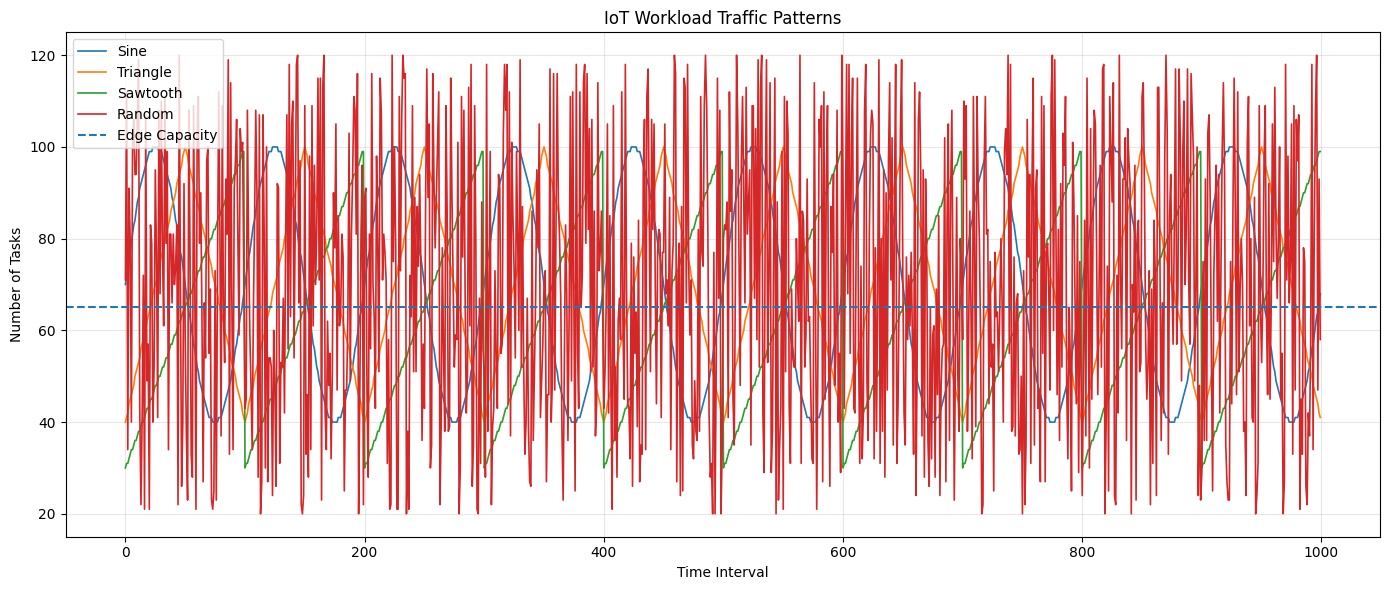


File berhasil disimpan:
- iot_workload_simulation.csv
- edge_cloud_configuration.csv


In [134]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. KONFIGURASI SIMULASI
# ==========================================

np.random.seed(42)

jumlah_interval = 1000

# Kapasitas pemrosesan per interval
EDGE_CAPACITY = 65
CLOUD_CAPACITY = 150

# Parameter jaringan
NETWORK_LATENCY_MS = 20

# Waktu pemrosesan dasar per task
EDGE_PROCESSING_MS = 5
CLOUD_PROCESSING_MS = 3

# ==========================================
# 2. GENERATE WORKLOAD IoT
# ==========================================

t = np.arange(jumlah_interval)

# Sine traffic
sine = 70 + 30 * np.sin(2 * np.pi * t / 100)

# Triangle traffic
triangle = 40 + 60 * (
    1 - np.abs(((t / 100) % 1) * 2 - 1)
)

# Sawtooth traffic
sawtooth = 30 + 70 * ((t % 100) / 100)

# Random traffic
random_traffic = np.random.randint(
    20, 121, size=jumlah_interval
)

# Membulatkan workload menjadi jumlah task
workload_data = {
    "Sine": np.clip(np.round(sine), 1, None).astype(int),
    "Triangle": np.clip(np.round(triangle), 1, None).astype(int),
    "Sawtooth": np.clip(np.round(sawtooth), 1, None).astype(int),
    "Random": random_traffic.astype(int)
}

# ==========================================
# 3. MEMBUAT DATAFRAME
# ==========================================

workload_df = pd.DataFrame({
    "Interval": t
})

for nama, data in workload_data.items():
    workload_df[nama] = data

print("===== WORKLOAD DATA VERIFICATION =====")
print("Jumlah interval:", jumlah_interval)
print("Jumlah dataset:", len(workload_data))

for nama, data in workload_data.items():
    print(f"\nDataset: {nama}")
    print("Total workload :", np.sum(data))
    print("Rata-rata       :", round(np.mean(data), 2))
    print("Minimum         :", np.min(data))
    print("Maksimum        :", np.max(data))

# ==========================================
# 4. KONFIGURASI EDGE-CLOUD
# ==========================================

system_config = pd.DataFrame({
    "Parameter": [
        "Edge Capacity",
        "Cloud Capacity",
        "Network Latency",
        "Edge Processing Time",
        "Cloud Processing Time"
    ],
    "Value": [
        EDGE_CAPACITY,
        CLOUD_CAPACITY,
        NETWORK_LATENCY_MS,
        EDGE_PROCESSING_MS,
        CLOUD_PROCESSING_MS
    ],
    "Unit": [
        "tasks/interval",
        "tasks/interval",
        "ms",
        "ms/task",
        "ms/task"
    ]
})

print("\n===== EDGE-CLOUD CONFIGURATION =====")
display(system_config)

# ==========================================
# 5. VISUALISASI WORKLOAD
# ==========================================

plt.figure(figsize=(14, 6))

for nama, data in workload_data.items():
    plt.plot(t, data, label=nama, linewidth=1.2)

plt.axhline(
    EDGE_CAPACITY,
    linestyle="--",
    label="Edge Capacity"
)

plt.title("IoT Workload Traffic Patterns")
plt.xlabel("Time Interval")
plt.ylabel("Number of Tasks")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# 6. SIMPAN DATA
# ==========================================

workload_df.to_csv(
    "iot_workload_simulation.csv",
    index=False
)

system_config.to_csv(
    "edge_cloud_configuration.csv",
    index=False
)

print("\nFile berhasil disimpan:")
print("- iot_workload_simulation.csv")
print("- edge_cloud_configuration.csv")


Simulasi distribusi workload selesai.
Jumlah dataset: 4
Jumlah metode: 3
Total eksperimen: 12

===== WORKLOAD DISTRIBUTION RESULTS =====


,Dataset,Method,Average Response Time (ms),Completion Rate (%),Average Edge Utilization (%),Average Cloud Utilization (%),Total Network Traffic (tasks),Total Dropped Tasks
0,Sine,Cloud-Only,23.0000,100.0,0.0000,46.6667,70000,0
1,Sine,Conventional Hybrid,14.0686,100.0,53.4769,23.4933,35240,0
2,Sine,Adaptive Hybrid,7.6391,100.0,87.8323,8.6060,12909,0
3,Triangle,Cloud-Only,23.0000,100.0,0.0000,46.6667,70000,0
4,Triangle,Conventional Hybrid,14.0550,100.0,53.5385,23.4667,35200,0
5,Triangle,Adaptive Hybrid,7.3324,100.0,90.9031,7.2753,10913,0
6,Sawtooth,Cloud-Only,23.0000,100.0,0.0000,43.1000,64650,0
7,Sawtooth,Conventional Hybrid,14.0698,100.0,49.3846,21.7000,32550,0
8,Sawtooth,Adaptive Hybrid,7.1436,100.0,84.7462,6.3767,9565,0
9,Random,Cloud-Only,23.0000,100.0,0.0000,46.6247,69937,0


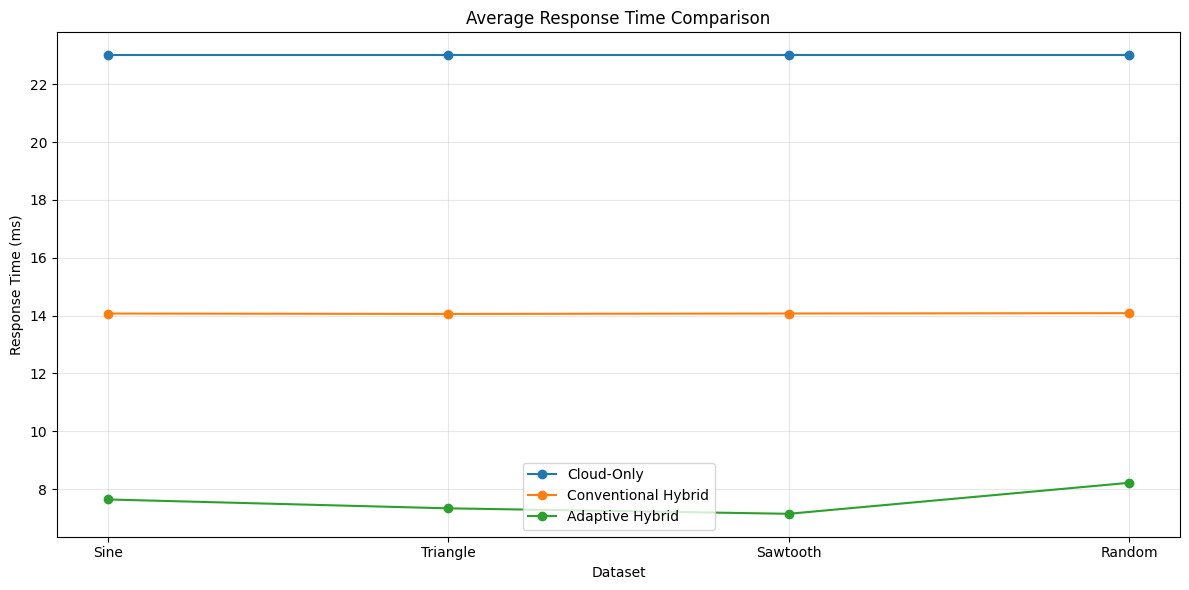

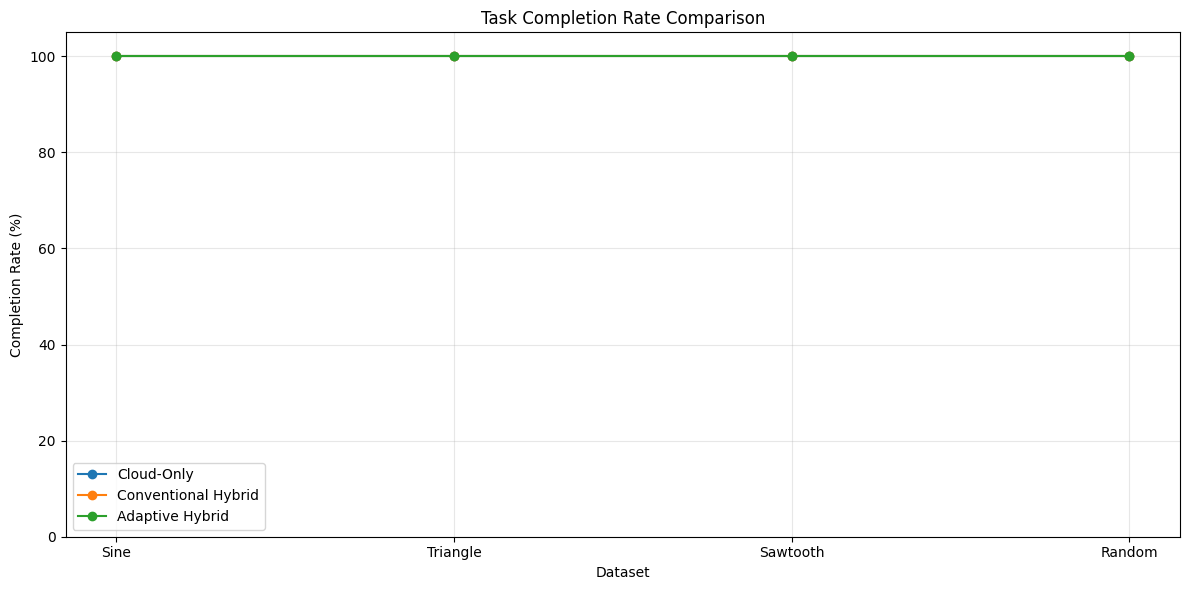


File berhasil disimpan:
adaptive_workload_distribution_results.csv


In [135]:

# ==========================================
# TAHAP 2: WORKLOAD DISTRIBUTION SIMULATION
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Konfigurasi
EDGE_CAPACITY = 65
CLOUD_CAPACITY = 150

EDGE_PROCESSING_MS = 5
CLOUD_PROCESSING_MS = 3
NETWORK_LATENCY_MS = 20

# ==========================================
# 1. FUNGSI SIMULASI
# ==========================================

def simulate_distribution(workload, method):

    results = []

    for i, actual_workload in enumerate(workload):

        actual_workload = int(actual_workload)

        # ----------------------------------
        # A. CLOUD-ONLY
        # ----------------------------------
        if method == "Cloud-Only":

            edge_tasks = 0
            cloud_tasks = min(
                actual_workload,
                CLOUD_CAPACITY
            )

        # ----------------------------------
        # B. CONVENTIONAL HYBRID
        # ----------------------------------
        elif method == "Conventional Hybrid":

            edge_target = int(actual_workload * 0.5)

            edge_tasks = min(
                edge_target,
                EDGE_CAPACITY
            )

            remaining = actual_workload - edge_tasks

            cloud_tasks = min(
                remaining,
                CLOUD_CAPACITY
            )

        # ----------------------------------
        # C. ADAPTIVE HYBRID
        # ----------------------------------
        elif method == "Adaptive Hybrid":

            # Prediksi menggunakan 5 interval sebelumnya
            if i == 0:
                predicted_workload = actual_workload
            else:
                history = workload[max(0, i-5):i]
                predicted_workload = np.mean(history)

            # Alokasi Edge berdasarkan prediksi
            edge_target = min(
                int(round(predicted_workload)),
                EDGE_CAPACITY
            )

            edge_tasks = min(
                actual_workload,
                edge_target
            )

            remaining = actual_workload - edge_tasks

            cloud_tasks = min(
                remaining,
                CLOUD_CAPACITY
            )

        else:
            raise ValueError("Metode tidak dikenal")

        # ----------------------------------
        # D. HITUNG METRIK
        # ----------------------------------

        completed_tasks = edge_tasks + cloud_tasks
        dropped_tasks = actual_workload - completed_tasks

        edge_time = edge_tasks * EDGE_PROCESSING_MS

        cloud_time = (
            cloud_tasks *
            (CLOUD_PROCESSING_MS + NETWORK_LATENCY_MS)
        )

        total_processing_time = edge_time + cloud_time

        if completed_tasks > 0:
            average_response_time = (
                total_processing_time / completed_tasks
            )
        else:
            average_response_time = 0

        if actual_workload > 0:
            completion_rate = (
                completed_tasks / actual_workload
            ) * 100
        else:
            completion_rate = 100

        edge_utilization = (
            edge_tasks / EDGE_CAPACITY
        ) * 100

        cloud_utilization = (
            cloud_tasks / CLOUD_CAPACITY
        ) * 100

        # Estimasi volume task yang dikirim ke Cloud
        network_traffic = cloud_tasks

        results.append({
            "Actual Workload": actual_workload,
            "Edge Tasks": edge_tasks,
            "Cloud Tasks": cloud_tasks,
            "Completed Tasks": completed_tasks,
            "Dropped Tasks": dropped_tasks,
            "Response Time (ms)": average_response_time,
            "Completion Rate (%)": completion_rate,
            "Edge Utilization (%)": edge_utilization,
            "Cloud Utilization (%)": cloud_utilization,
            "Network Traffic (tasks)": network_traffic
        })

    return pd.DataFrame(results)


# ==========================================
# 2. JALANKAN SEMUA METODE
# ==========================================

methods = [
    "Cloud-Only",
    "Conventional Hybrid",
    "Adaptive Hybrid"
]

all_results = {}

for dataset_name, workload in workload_data.items():

    for method in methods:

        result = simulate_distribution(
            workload,
            method
        )

        all_results[(dataset_name, method)] = result


print("Simulasi distribusi workload selesai.")
print("Jumlah dataset:", len(workload_data))
print("Jumlah metode:", len(methods))
print("Total eksperimen:", len(all_results))


# ==========================================
# 3. AGREGASI HASIL
# ==========================================

summary = []

for (dataset_name, method), result in all_results.items():

    summary.append({
        "Dataset": dataset_name,
        "Method": method,
        "Average Response Time (ms)": result[
            "Response Time (ms)"
        ].mean(),
        "Completion Rate (%)": result[
            "Completion Rate (%)"
        ].mean(),
        "Average Edge Utilization (%)": result[
            "Edge Utilization (%)"
        ].mean(),
        "Average Cloud Utilization (%)": result[
            "Cloud Utilization (%)"
        ].mean(),
        "Total Network Traffic (tasks)": result[
            "Network Traffic (tasks)"
        ].sum(),
        "Total Dropped Tasks": result[
            "Dropped Tasks"
        ].sum()
    })

summary_df = pd.DataFrame(summary)

print("\n===== WORKLOAD DISTRIBUTION RESULTS =====")
display(summary_df.round(4))


# ==========================================
# 4. VISUALISASI RESPONSE TIME
# ==========================================

plt.figure(figsize=(12, 6))

for method in methods:

    values = summary_df[
        summary_df["Method"] == method
    ]

    plt.plot(
        values["Dataset"],
        values["Average Response Time (ms)"],
        marker="o",
        label=method
    )

plt.title("Average Response Time Comparison")
plt.xlabel("Dataset")
plt.ylabel("Response Time (ms)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ==========================================
# 5. VISUALISASI COMPLETION RATE
# ==========================================

plt.figure(figsize=(12, 6))

for method in methods:

    values = summary_df[
        summary_df["Method"] == method
    ]

    plt.plot(
        values["Dataset"],
        values["Completion Rate (%)"],
        marker="o",
        label=method
    )

plt.title("Task Completion Rate Comparison")
plt.xlabel("Dataset")
plt.ylabel("Completion Rate (%)")
plt.ylim(0, 105)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ==========================================
# 6. SIMPAN HASIL
# ==========================================

summary_df.to_csv(
    "adaptive_workload_distribution_results.csv",
    index=False
)

print("\nFile berhasil disimpan:")
print("adaptive_workload_distribution_results.csv")


===== STRESS TEST VERIFICATION =====
Datasets: 4
Scenarios: 5
Methods: 3
Total experiments: 60

===== STRESS TEST RESULTS =====


,Dataset,Scenario,Method,Average Response Time (ms),Completion Rate (%),Average Edge Utilization (%),Average Cloud Utilization (%),Total Network Traffic (tasks),Total Dropped Tasks
0,Sine,Normal,Cloud-Only,23.0000,100.0000,0.0000,46.6667,70000,0
1,Sine,Normal,Conventional Hybrid,14.0686,100.0000,53.4769,23.4933,35240,0
2,Sine,Normal,Adaptive Hybrid,7.6391,100.0000,87.8323,8.6060,12909,0
3,Sine,High Workload,Cloud-Only,23.0000,74.8482,0.0000,96.4800,144720,65280
4,Sine,High Workload,Conventional Hybrid,16.4079,90.6662,99.1538,79.5867,119380,26170
5,Sine,High Workload,Adaptive Hybrid,16.3267,90.6662,100.0000,79.2200,118830,26170
6,Sine,Limited Edge,Cloud-Only,23.0000,100.0000,0.0000,46.6667,70000,0
7,Sine,Limited Edge,Conventional Hybrid,16.2925,100.0000,96.2000,30.6333,45950,0
8,Sine,Limited Edge,Adaptive Hybrid,15.8862,100.0000,100.0000,30.0000,45000,0
9,Sine,High Latency,Cloud-Only,103.0000,100.0000,0.0000,46.6667,70000,0



===== SCENARIO SUMMARY =====


,Scenario,Method,Average Response Time (ms),Completion Rate (%),Total Dropped Tasks,Total Network Traffic (tasks)
0,Combined Stress,Adaptive Hybrid,86.9556,82.6941,186640,537121
1,Combined Stress,Cloud-Only,103.0000,75.3494,255069,568692
2,Combined Stress,Conventional Hybrid,86.9556,82.6941,186640,537121
3,High Latency,Adaptive Hybrid,19.0595,100.0000,0,51049
4,High Latency,Cloud-Only,103.0000,100.0000,0,274587
5,High Latency,Conventional Hybrid,54.3736,100.0000,0,138209
6,High Workload,Adaptive Hybrid,16.0319,91.3453,99322,464545
7,High Workload,Cloud-Only,23.0000,75.3494,255069,568692
8,High Workload,Conventional Hybrid,16.4079,91.3453,99322,471799
9,Limited Edge,Adaptive Hybrid,15.5371,100.0000,0,174788


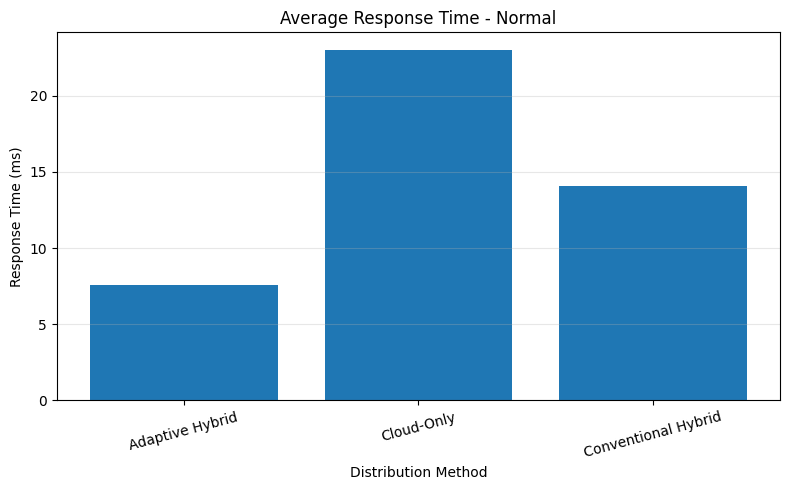

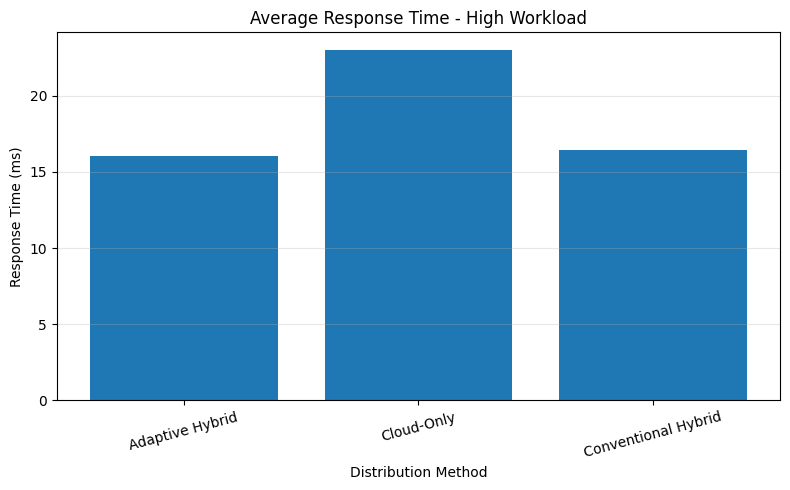

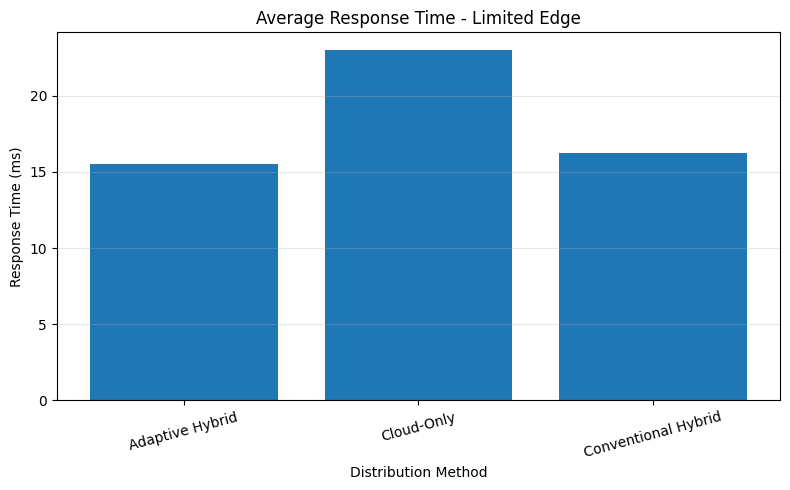

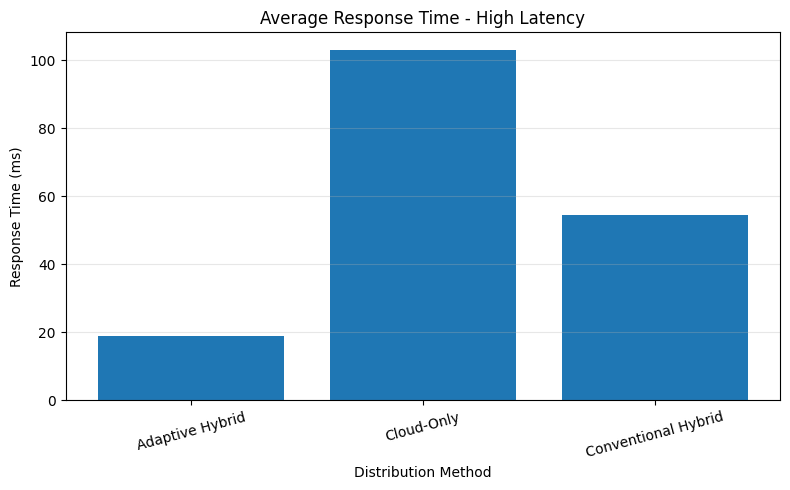

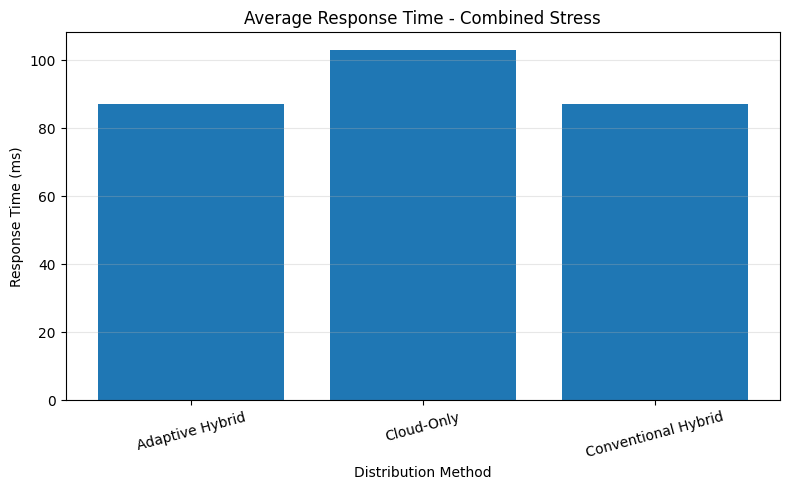


File berhasil disimpan:
- stress_testing_detailed_results.csv
- stress_testing_summary.csv


In [136]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. STRESS TEST CONFIGURATION
# ==========================================

stress_scenarios = {
    "Normal": {
        "workload_multiplier": 1,
        "edge_capacity": 65,
        "cloud_capacity": 150,
        "network_latency": 20
    },
    "High Workload": {
        "workload_multiplier": 3,
        "edge_capacity": 65,
        "cloud_capacity": 150,
        "network_latency": 20
    },
    "Limited Edge": {
        "workload_multiplier": 1,
        "edge_capacity": 25,
        "cloud_capacity": 150,
        "network_latency": 20
    },
    "High Latency": {
        "workload_multiplier": 1,
        "edge_capacity": 65,
        "cloud_capacity": 150,
        "network_latency": 100
    },
    "Combined Stress": {
        "workload_multiplier": 3,
        "edge_capacity": 25,
        "cloud_capacity": 150,
        "network_latency": 100
    }
}

# ==========================================
# 2. STRESS TEST SIMULATION FUNCTION
# ==========================================

def run_stress_simulation(
    workload,
    method,
    edge_capacity,
    cloud_capacity,
    network_latency
):

    results = []

    for i, actual_workload in enumerate(workload):

        actual_workload = int(actual_workload)

        # Cloud-Only
        if method == "Cloud-Only":

            edge_tasks = 0
            cloud_tasks = min(
                actual_workload,
                cloud_capacity
            )

        # Conventional Hybrid
        elif method == "Conventional Hybrid":

            edge_target = int(actual_workload * 0.5)

            edge_tasks = min(
                edge_target,
                edge_capacity
            )

            remaining = actual_workload - edge_tasks

            cloud_tasks = min(
                remaining,
                cloud_capacity
            )

        # Adaptive Hybrid
        elif method == "Adaptive Hybrid":

            if i == 0:
                predicted_workload = actual_workload
            else:
                history = workload[max(0, i-5):i]
                predicted_workload = np.mean(history)

            edge_target = min(
                int(round(predicted_workload)),
                edge_capacity
            )

            edge_tasks = min(
                actual_workload,
                edge_target
            )

            remaining = actual_workload - edge_tasks

            cloud_tasks = min(
                remaining,
                cloud_capacity
            )

        else:
            raise ValueError("Unknown method")

        # Completed and dropped tasks
        completed = edge_tasks + cloud_tasks
        dropped = actual_workload - completed

        # Utilization
        edge_util = (
            edge_tasks / edge_capacity * 100
            if edge_capacity > 0 else 0
        )

        cloud_util = (
            cloud_tasks / cloud_capacity * 100
            if cloud_capacity > 0 else 0
        )

        # Response time approximation:
        # processing time + network latency for Cloud tasks
        edge_time = edge_tasks * 5

        cloud_time = cloud_tasks * (
            3 + network_latency
        )

        total_time = edge_time + cloud_time

        response_time = (
            total_time / completed
            if completed > 0 else 0
        )

        completion_rate = (
            completed / actual_workload * 100
            if actual_workload > 0 else 100
        )

        results.append({
            "Actual Workload": actual_workload,
            "Edge Tasks": edge_tasks,
            "Cloud Tasks": cloud_tasks,
            "Completed Tasks": completed,
            "Dropped Tasks": dropped,
            "Response Time (ms)": response_time,
            "Completion Rate (%)": completion_rate,
            "Edge Utilization (%)": edge_util,
            "Cloud Utilization (%)": cloud_util,
            "Network Traffic (tasks)": cloud_tasks
        })

    return pd.DataFrame(results)


# ==========================================
# 3. EXECUTE ALL STRESS SCENARIOS
# ==========================================

stress_results = []

stress_detail = {}

methods = [
    "Cloud-Only",
    "Conventional Hybrid",
    "Adaptive Hybrid"
]

for dataset_name, original_workload in workload_data.items():

    for scenario_name, config in stress_scenarios.items():

        stressed_workload = (
            original_workload *
            config["workload_multiplier"]
        ).astype(int)

        for method in methods:

            result = run_stress_simulation(
                workload=stressed_workload,
                method=method,
                edge_capacity=config["edge_capacity"],
                cloud_capacity=config["cloud_capacity"],
                network_latency=config["network_latency"]
            )

            stress_detail[
                (dataset_name, scenario_name, method)
            ] = result

            stress_results.append({
                "Dataset": dataset_name,
                "Scenario": scenario_name,
                "Method": method,
                "Average Response Time (ms)": result[
                    "Response Time (ms)"
                ].mean(),
                "Completion Rate (%)": result[
                    "Completion Rate (%)"
                ].mean(),
                "Average Edge Utilization (%)": result[
                    "Edge Utilization (%)"
                ].mean(),
                "Average Cloud Utilization (%)": result[
                    "Cloud Utilization (%)"
                ].mean(),
                "Total Network Traffic (tasks)": result[
                    "Network Traffic (tasks)"
                ].sum(),
                "Total Dropped Tasks": result[
                    "Dropped Tasks"
                ].sum()
            })

stress_df = pd.DataFrame(stress_results)

# ==========================================
# 4. DISPLAY RESULTS
# ==========================================

print("===== STRESS TEST VERIFICATION =====")
print("Datasets:", len(workload_data))
print("Scenarios:", len(stress_scenarios))
print("Methods:", len(methods))
print("Total experiments:", len(stress_df))

print("\n===== STRESS TEST RESULTS =====")
display(stress_df.round(4))

# ==========================================
# 5. SUMMARY PER SCENARIO
# ==========================================

scenario_summary = stress_df.groupby(
    ["Scenario", "Method"]
).agg({
    "Average Response Time (ms)": "mean",
    "Completion Rate (%)": "mean",
    "Total Dropped Tasks": "sum",
    "Total Network Traffic (tasks)": "sum"
}).reset_index()

print("\n===== SCENARIO SUMMARY =====")
display(scenario_summary.round(4))

# ==========================================
# 6. VISUALIZE RESPONSE TIME
# ==========================================

for scenario in stress_scenarios:

    subset = scenario_summary[
        scenario_summary["Scenario"] == scenario
    ]

    plt.figure(figsize=(8, 5))

    plt.bar(
        subset["Method"],
        subset["Average Response Time (ms)"]
    )

    plt.title(
        f"Average Response Time - {scenario}"
    )

    plt.xlabel("Distribution Method")
    plt.ylabel("Response Time (ms)")
    plt.xticks(rotation=15)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


# ==========================================
# 7. SAVE RESULTS
# ==========================================

stress_df.to_csv(
    "stress_testing_detailed_results.csv",
    index=False
)

scenario_summary.to_csv(
    "stress_testing_summary.csv",
    index=False
)

print("\nFile berhasil disimpan:")
print("- stress_testing_detailed_results.csv")
print("- stress_testing_summary.csv")


===== CAPACITY SENSITIVITY RESULTS =====
Total experiments: 48


,Edge Capacity,Method,Average Response Time (ms),Completion Rate (%),Total Dropped Tasks,Total Network Traffic (tasks)
0,25,Adaptive Hybrid,86.9556,82.6941,186640,537121
1,25,Cloud-Only,103.0000,75.3494,255069,568692
2,25,Conventional Hybrid,86.9556,82.6941,186640,537121
3,40,Adaptive Hybrid,78.3899,86.3534,150687,513074
4,40,Cloud-Only,103.0000,75.3494,255069,568692
5,40,Conventional Hybrid,78.5807,86.3534,150687,513577
6,65,Adaptive Hybrid,65.0624,91.3453,99322,464545
7,65,Cloud-Only,103.0000,75.3494,255069,568692
8,65,Conventional Hybrid,67.1094,91.3453,99322,471799
9,80,Adaptive Hybrid,57.6450,93.7343,73625,431110


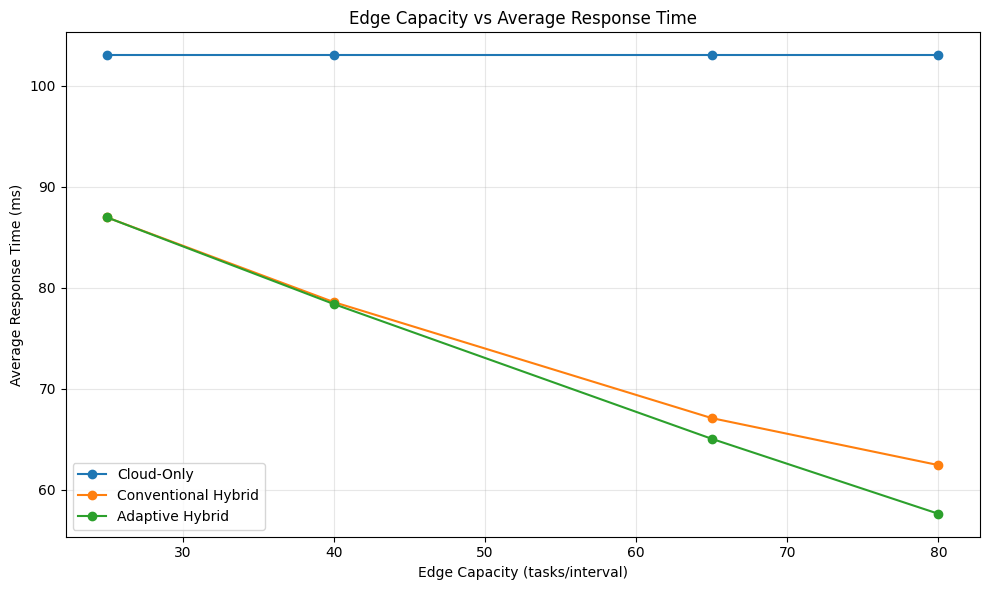

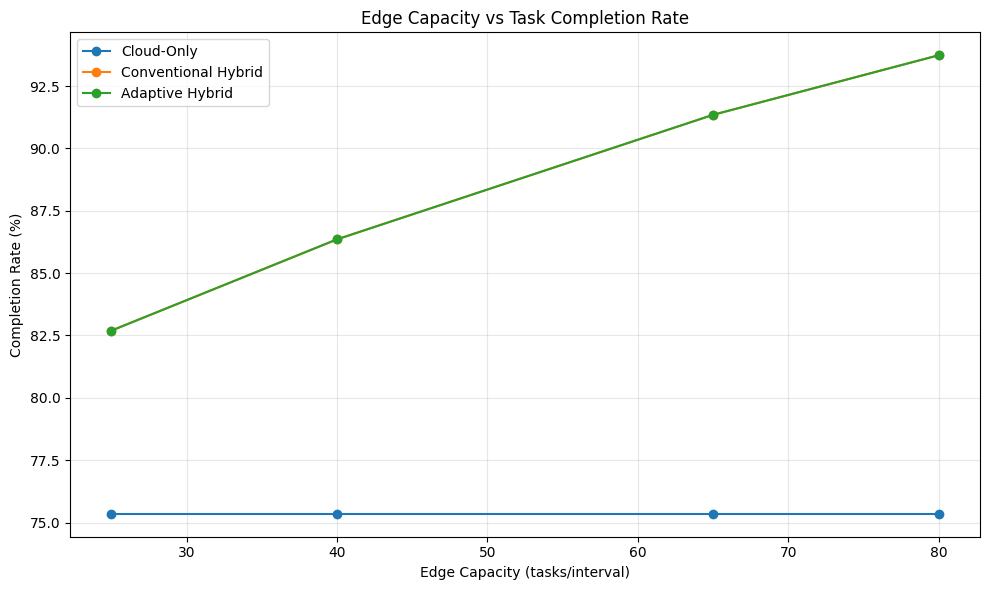


File berhasil disimpan:
- capacity_sensitivity_detailed.csv
- capacity_sensitivity_summary.csv


In [137]:

# ==========================================
# CAPACITY SENSITIVITY ANALYSIS
# ==========================================

edge_capacity_values = [25, 40, 65, 80]

CLOUD_CAPACITY = 150
NETWORK_LATENCY_MS = 100

sensitivity_results = []

for dataset_name, original_workload in workload_data.items():

    stressed_workload = (
        original_workload * 3
    ).astype(int)

    for edge_capacity in edge_capacity_values:

        for method in methods:

            result = run_stress_simulation(
                workload=stressed_workload,
                method=method,
                edge_capacity=edge_capacity,
                cloud_capacity=CLOUD_CAPACITY,
                network_latency=NETWORK_LATENCY_MS
            )

            sensitivity_results.append({
                "Dataset": dataset_name,
                "Edge Capacity": edge_capacity,
                "Method": method,
                "Average Response Time (ms)": result[
                    "Response Time (ms)"
                ].mean(),
                "Completion Rate (%)": result[
                    "Completion Rate (%)"
                ].mean(),
                "Total Dropped Tasks": result[
                    "Dropped Tasks"
                ].sum(),
                "Total Network Traffic (tasks)": result[
                    "Network Traffic (tasks)"
                ].sum()
            })

sensitivity_df = pd.DataFrame(sensitivity_results)

# ==========================================
# SUMMARY
# ==========================================

sensitivity_summary = sensitivity_df.groupby(
    ["Edge Capacity", "Method"]
).agg({
    "Average Response Time (ms)": "mean",
    "Completion Rate (%)": "mean",
    "Total Dropped Tasks": "sum",
    "Total Network Traffic (tasks)": "sum"
}).reset_index()

print("===== CAPACITY SENSITIVITY RESULTS =====")
print("Total experiments:", len(sensitivity_df))
display(sensitivity_summary.round(4))

# ==========================================
# RESPONSE TIME GRAPH
# ==========================================

plt.figure(figsize=(10, 6))

for method in methods:

    subset = sensitivity_summary[
        sensitivity_summary["Method"] == method
    ]

    plt.plot(
        subset["Edge Capacity"],
        subset["Average Response Time (ms)"],
        marker="o",
        label=method
    )

plt.title("Edge Capacity vs Average Response Time")
plt.xlabel("Edge Capacity (tasks/interval)")
plt.ylabel("Average Response Time (ms)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# COMPLETION RATE GRAPH
# ==========================================

plt.figure(figsize=(10, 6))

for method in methods:

    subset = sensitivity_summary[
        sensitivity_summary["Method"] == method
    ]

    plt.plot(
        subset["Edge Capacity"],
        subset["Completion Rate (%)"],
        marker="o",
        label=method
    )

plt.title("Edge Capacity vs Task Completion Rate")
plt.xlabel("Edge Capacity (tasks/interval)")
plt.ylabel("Completion Rate (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ==========================================
# SAVE
# ==========================================

sensitivity_df.to_csv(
    "capacity_sensitivity_detailed.csv",
    index=False
)

sensitivity_summary.to_csv(
    "capacity_sensitivity_summary.csv",
    index=False
)

print("\nFile berhasil disimpan:")
print("- capacity_sensitivity_detailed.csv")
print("- capacity_sensitivity_summary.csv")


In [138]:

# ==========================================
# CHECK MODEL AND DATA COMPATIBILITY
# ==========================================

print("===== MODEL AVAILABILITY =====")

for dataset_name in models_all:

    print(f"\nDataset: {dataset_name}")

    for model_name, model_obj in models_all[dataset_name].items():

        print(
            model_name,
            "| Input:", model_obj.input_shape,
            "| Output:", model_obj.output_shape
        )

print("\n===== ORIGINAL TEST DATA RANGE =====")

for dataset_name in datasets_test:

    X = datasets_test[dataset_name]
    y = targets_test[dataset_name]

    print(f"\nDataset: {dataset_name}")
    print("X shape:", X.shape)
    print("X min/max:", np.min(X), np.max(X))
    print("y shape:", y.shape)
    print("y min/max:", np.min(y), np.max(y))

print("\n===== SIMULATION WORKLOAD RANGE =====")

for dataset_name, data in workload_data.items():

    print(f"\nDataset: {dataset_name}")
    print("Shape:", data.shape)
    print("Min:", np.min(data))
    print("Max:", np.max(data))
    print("Mean:", np.mean(data))

print("\n===== MODEL COMPATIBILITY CHECK COMPLETE =====")


===== MODEL AVAILABILITY =====

Dataset: Sine
1DCNN | Input: (None, 128, 1) | Output: (None, 5)
LSTM | Input: (None, 128, 1) | Output: (None, 5)
Transformer | Input: (None, 128, 1) | Output: (None, 5)
Transformer-PE | Input: (None, 128, 1) | Output: (None, 5)

Dataset: Triangle
1DCNN | Input: (None, 128, 1) | Output: (None, 5)
LSTM | Input: (None, 128, 1) | Output: (None, 5)
Transformer | Input: (None, 128, 1) | Output: (None, 5)
Transformer-PE | Input: (None, 128, 1) | Output: (None, 5)

Dataset: Sawtooth
1DCNN | Input: (None, 128, 1) | Output: (None, 5)
LSTM | Input: (None, 128, 1) | Output: (None, 5)
Transformer | Input: (None, 128, 1) | Output: (None, 5)
Transformer-PE | Input: (None, 128, 1) | Output: (None, 5)

Dataset: Random
1DCNN | Input: (None, 128, 1) | Output: (None, 5)
LSTM | Input: (None, 128, 1) | Output: (None, 5)
Transformer | Input: (None, 128, 1) | Output: (None, 5)
Transformer-PE | Input: (None, 128, 1) | Output: (None, 5)

===== ORIGINAL TEST DATA RANGE =====

Data

In [139]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error

prediction_test_results = []
predictions_simulation = {}

for dataset_name, workload in workload_data.items():

    # Ambil model Transformer-PE sebagai model awal pengujian
    model = models_all[dataset_name]["Transformer-PE"]

    workload = np.asarray(workload, dtype=np.float32)

    # Normalisasi workload ke rentang 0-1
    min_value = workload.min()
    max_value = workload.max()

    normalized = (
        (workload - min_value) / (max_value - min_value)
    )

    # Membuat window input 128 dan target 5 langkah
    X_sim = []
    y_actual = []

    for i in range(len(normalized) - 128 - 5 + 1):
        X_sim.append(normalized[i:i+128])
        y_actual.append(normalized[i+128:i+128+5])

    X_sim = np.array(X_sim).reshape(-1, 128, 1)
    y_actual = np.array(y_actual)

    # Prediksi menggunakan Transformer-PE
    y_pred_normalized = model.predict(
        X_sim,
        batch_size=128,
        verbose=0
    )

    # Kembalikan hasil ke skala jumlah task
    y_pred = (
        y_pred_normalized * (max_value - min_value)
        + min_value
    )

    y_actual_original = (
        y_actual * (max_value - min_value)
        + min_value
    )

    # Evaluasi menggunakan prediksi langkah pertama
    actual_first = y_actual_original[:, 0]
    predicted_first = y_pred[:, 0]

    rmse = np.sqrt(
        mean_squared_error(actual_first, predicted_first)
    )

    mae = mean_absolute_error(
        actual_first, predicted_first
    )

    prediction_test_results.append({
        "Dataset": dataset_name,
        "Model": "Transformer-PE",
        "RMSE": rmse,
        "MAE": mae,
        "Jumlah Prediksi": len(predicted_first)
    })

    predictions_simulation[dataset_name] = {
        "actual": actual_first,
        "predicted": predicted_first
    }

prediction_test_df = pd.DataFrame(prediction_test_results)

print("===== SIMULATION WORKLOAD PREDICTION =====")
display(prediction_test_df)

prediction_test_df.to_csv(
    "simulation_workload_prediction.csv",
    index=False
)

print("File berhasil disimpan.")


===== SIMULATION WORKLOAD PREDICTION =====


,Dataset,Model,RMSE,MAE,Jumlah Prediksi
0,Sine,Transformer-PE,8.655408,7.324224,868
1,Triangle,Transformer-PE,20.038743,18.016460,868
2,Sawtooth,Transformer-PE,29.591582,24.485649,868
3,Random,Transformer-PE,29.996416,25.923992,868


File berhasil disimpan.


In [140]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error

model_comparison_results = []
predictions_all_simulation = {}

for dataset_name, workload in workload_data.items():

    workload = np.asarray(workload, dtype=np.float32)

    # Normalisasi ke rentang 0-1
    min_value = workload.min()
    max_value = workload.max()

    normalized = (
        (workload - min_value) / (max_value - min_value)
    )

    # Membuat input 128 langkah dan target 5 langkah
    X_sim = []
    y_actual = []

    for i in range(len(normalized) - 128 - 5 + 1):
        X_sim.append(normalized[i:i+128])
        y_actual.append(normalized[i+128:i+128+5])

    X_sim = np.array(X_sim).reshape(-1, 128, 1)
    y_actual = np.array(y_actual)

    # Kembalikan target ke skala workload asli
    y_actual_original = (
        y_actual * (max_value - min_value) + min_value
    )

    predictions_all_simulation[dataset_name] = {}

    for model_name, model in models_all[dataset_name].items():

        y_pred_normalized = model.predict(
            X_sim,
            batch_size=128,
            verbose=0
        )

        y_pred = (
            y_pred_normalized * (max_value - min_value)
            + min_value
        )

        # Evaluasi horizon pertama
        actual = y_actual_original[:, 0]
        predicted = y_pred[:, 0]

        rmse = np.sqrt(
            mean_squared_error(actual, predicted)
        )

        mae = mean_absolute_error(actual, predicted)

        model_comparison_results.append({
            "Dataset": dataset_name,
            "Model": model_name,
            "RMSE": rmse,
            "MAE": mae
        })

        predictions_all_simulation[dataset_name][model_name] = {
            "actual": actual,
            "predicted": predicted
        }

comparison_simulation_df = pd.DataFrame(
    model_comparison_results
)

print("===== PERBANDINGAN MODEL PADA WORKLOAD SIMULASI =====")
display(
    comparison_simulation_df.sort_values(
        ["Dataset", "RMSE"]
    ).reset_index(drop=True)
)

# Rata-rata performa setiap model
comparison_average = (
    comparison_simulation_df
    .groupby("Model")[["RMSE", "MAE"]]
    .mean()
    .sort_values("RMSE")
    .reset_index()
)

print("===== RATA-RATA PERFORMA MODEL =====")
display(comparison_average)

comparison_simulation_df.to_csv(
    "model_comparison_simulation.csv",
    index=False
)

comparison_average.to_csv(
    "model_comparison_simulation_average.csv",
    index=False
)

print("File berhasil disimpan.")


===== PERBANDINGAN MODEL PADA WORKLOAD SIMULASI =====


,Dataset,Model,RMSE,MAE
0,Random,Transformer-PE,29.996416,25.923992
1,Random,LSTM,29.998176,25.924688
2,Random,Transformer,30.114745,26.004644
3,Random,1DCNN,30.327445,26.179647
4,Sawtooth,LSTM,6.986930,3.785588
5,Sawtooth,1DCNN,10.435538,6.152337
6,Sawtooth,Transformer,22.688908,18.861258
7,Sawtooth,Transformer-PE,29.591582,24.485649
8,Sine,1DCNN,3.427579,2.840135
9,Sine,LSTM,4.542454,4.150311


===== RATA-RATA PERFORMA MODEL =====


,Model,RMSE,MAE
0,LSTM,13.387477,11.145255
1,1DCNN,16.699681,13.807863
2,Transformer,20.932165,17.992498
3,Transformer-PE,22.070537,18.937582


File berhasil disimpan.


In [141]:

import numpy as np
import pandas as pd

# ==========================================
# KONFIGURASI SIMULASI
# ==========================================

EDGE_CAPACITIES = [25, 40, 65, 80]
CLOUD_CAPACITY = 150
NETWORK_LATENCY = 100
EDGE_PROCESSING = 5
CLOUD_PROCESSING = 3
WORKLOAD_MULTIPLIER = 3

simulation_methods = [
    "Cloud-Only",
    "Conventional Hybrid",
    "Adaptive Moving Average",
    "Adaptive LSTM"
]

lstm_scheduler_results = []

# ==========================================
# EKSPERIMEN SETIAP DATASET
# ==========================================

for dataset_name, original_workload in workload_data.items():

    print("Processing:", dataset_name)

    workload = (
        np.asarray(original_workload, dtype=np.float32)
        * WORKLOAD_MULTIPLIER
    )

    # Normalisasi workload
    min_value = workload.min()
    max_value = workload.max()

    normalized = (
        (workload - min_value) /
        (max_value - min_value)
    )

    # Membuat seluruh window input LSTM
    X_windows = []

    for t in range(128, len(workload)):
        X_windows.append(normalized[t-128:t])

    X_windows = np.array(
        X_windows, dtype=np.float32
    ).reshape(-1, 128, 1)

    # Prediksi menggunakan model LSTM yang sudah dilatih
    lstm_model = models_lstm[dataset_name]

    predictions_normalized = lstm_model.predict(
        X_windows,
        batch_size=128,
        verbose=0
    )

    # Menggunakan prediksi horizon pertama
    predictions = (
        np.clip(predictions_normalized[:, 0], 0, 1)
        * (max_value - min_value)
        + min_value
    )

    # ======================================
    # SIMULASI SCHEDULER
    # ======================================

    for edge_capacity in EDGE_CAPACITIES:

        for method in simulation_methods:

            response_times = []
            total_completed = 0
            total_dropped = 0
            total_network = 0
            total_arrivals = 0

            for idx, t in enumerate(range(128, len(workload))):

                actual_tasks = int(workload[t])
                total_arrivals += actual_tasks

                # Prediksi Moving Average
                moving_average = np.mean(
                    workload[max(0, t-5):t]
                )

                # Prediksi LSTM
                lstm_prediction = predictions[idx]

                # ==================================
                # MENENTUKAN TARGET EDGE
                # ==================================

                if method == "Cloud-Only":

                    edge_tasks = 0

                elif method == "Conventional Hybrid":

                    edge_target = actual_tasks * 0.5
                    edge_tasks = min(
                        int(edge_target),
                        edge_capacity,
                        actual_tasks
                    )

                elif method == "Adaptive Moving Average":

                    edge_target = min(
                        moving_average,
                        edge_capacity,
                        actual_tasks
                    )

                    edge_tasks = int(edge_target)

                elif method == "Adaptive LSTM":

                    edge_target = min(
                        lstm_prediction,
                        edge_capacity,
                        actual_tasks
                    )

                    edge_tasks = int(edge_target)

                # ==================================
                # ALOKASI CLOUD
                # ==================================

                remaining_tasks = actual_tasks - edge_tasks

                cloud_tasks = min(
                    remaining_tasks,
                    CLOUD_CAPACITY
                )

                completed = edge_tasks + cloud_tasks
                dropped = actual_tasks - completed

                # ==================================
                # MENGHITUNG METRIK
                # ==================================

                if completed > 0:

                    response_time = (
                        edge_tasks * EDGE_PROCESSING
                        + cloud_tasks * (
                            CLOUD_PROCESSING + NETWORK_LATENCY
                        )
                    ) / completed

                    response_times.append(response_time)

                total_completed += completed
                total_dropped += dropped
                total_network += cloud_tasks

            completion_rate = (
                total_completed / total_arrivals * 100
            )

            avg_response = (
                np.mean(response_times)
                if response_times else 0
            )

            lstm_scheduler_results.append({
                "Dataset": dataset_name,
                "Edge Capacity": edge_capacity,
                "Method": method,
                "Average Response Time (ms)": avg_response,
                "Completion Rate (%)": completion_rate,
                "Total Dropped Tasks": total_dropped,
                "Total Network Traffic (tasks)": total_network
            })

# ==========================================
# HASIL EKSPERIMEN
# ==========================================

lstm_scheduler_df = pd.DataFrame(
    lstm_scheduler_results
)

lstm_scheduler_summary = (
    lstm_scheduler_df
    .groupby(["Edge Capacity", "Method"])
    .agg({
        "Average Response Time (ms)": "mean",
        "Completion Rate (%)": "mean",
        "Total Dropped Tasks": "sum",
        "Total Network Traffic (tasks)": "sum"
    })
    .reset_index()
)

print("===== LSTM ADAPTIVE SCHEDULER RESULTS =====")
print("Total experiments:", len(lstm_scheduler_df))
display(lstm_scheduler_df)

print("===== SUMMARY RESULTS =====")
display(lstm_scheduler_summary)

# Simpan hasil
lstm_scheduler_df.to_csv(
    "lstm_scheduler_detailed.csv",
    index=False
)

lstm_scheduler_summary.to_csv(
    "lstm_scheduler_summary.csv",
    index=False
)

print("File berhasil disimpan:")
print("- lstm_scheduler_detailed.csv")
print("- lstm_scheduler_summary.csv")


Processing: Sine
Processing: Triangle
Processing: Sawtooth
Processing: Random
===== LSTM ADAPTIVE SCHEDULER RESULTS =====
Total experiments: 64


,Dataset,Edge Capacity,Method,Average Response Time (ms),Completion Rate (%),Total Dropped Tasks,Total Network Traffic (tasks)
0,Sine,25,Cloud-Only,103.000000,69.461711,55416,126048
1,Sine,25,Conventional Hybrid,87.523964,77.482586,40861,118803
2,Sine,25,Adaptive Moving Average,87.523964,77.482586,40861,118803
3,Sine,25,Adaptive LSTM,87.523964,77.482586,40861,118803
4,Sine,40,Cloud-Only,103.000000,69.461711,55416,126048
...,...,...,...,...,...,...,...
59,Random,65,Adaptive LSTM,61.013836,82.611637,31876,94855
60,Random,80,Cloud-Only,103.000000,64.520669,65040,118278
61,Random,80,Conventional Hybrid,62.404211,85.875910,25892,95434
62,Random,80,Adaptive Moving Average,53.612752,85.875910,25892,88474


===== SUMMARY RESULTS =====


,Edge Capacity,Method,Average Response Time (ms),Completion Rate (%),Total Dropped Tasks,Total Network Traffic (tasks)
0,25,Adaptive LSTM,87.009549,77.344044,163593,469510
1,25,Adaptive Moving Average,87.009549,77.344044,163593,469510
2,25,Cloud-Only,103.000000,69.014050,223584,496719
3,25,Conventional Hybrid,87.009549,77.344044,163593,469510
4,40,Adaptive LSTM,78.481607,81.717630,132085,448698
5,40,Adaptive Moving Average,78.481607,81.717630,132085,448698
6,40,Cloud-Only,103.000000,69.014050,223584,496719
7,40,Conventional Hybrid,78.662954,81.717630,132085,449114
8,65,Adaptive LSTM,65.220976,87.960020,87090,406586
9,65,Adaptive Moving Average,65.220976,87.960020,87090,406586


File berhasil disimpan:
- lstm_scheduler_detailed.csv
- lstm_scheduler_summary.csv


In [142]:

diagnostic_results = []

for dataset_name, original_workload in workload_data.items():

    workload = (
        np.asarray(original_workload, dtype=np.float32) * 3
    )

    min_value = workload.min()
    max_value = workload.max()

    normalized = (
        (workload - min_value) / (max_value - min_value)
    )

    # Input LSTM
    X_windows = np.array([
        normalized[t-128:t]
        for t in range(128, len(workload))
    ]).reshape(-1, 128, 1)

    # Prediksi LSTM
    model = models_lstm[dataset_name]

    pred_norm = model.predict(
        X_windows, batch_size=128, verbose=0
    )

    pred_lstm = (
        pred_norm[:, 0] * (max_value - min_value)
        + min_value
    )

    for edge_capacity in [25, 40, 65, 80]:

        allocations_ma = []
        allocations_lstm = []
        ma_predictions = []

        for idx, t in enumerate(range(128, len(workload))):

            ma = np.mean(workload[t-5:t])
            lstm = pred_lstm[idx]

            ma_edge = int(min(ma, edge_capacity, workload[t]))
            lstm_edge = int(min(lstm, edge_capacity, workload[t]))

            ma_predictions.append(ma)
            allocations_ma.append(ma_edge)
            allocations_lstm.append(lstm_edge)

        allocations_ma = np.array(allocations_ma)
        allocations_lstm = np.array(allocations_lstm)

        diagnostic_results.append({
            "Dataset": dataset_name,
            "Edge Capacity": edge_capacity,
            "MA Prediction Mean": np.mean(ma_predictions),
            "LSTM Prediction Mean": np.mean(pred_lstm),
            "MA Edge Allocation Mean": np.mean(allocations_ma),
            "LSTM Edge Allocation Mean": np.mean(allocations_lstm),
            "Different Decisions": np.sum(
                allocations_ma != allocations_lstm
            ),
            "Total Intervals": len(allocations_ma)
        })

diagnostic_df = pd.DataFrame(diagnostic_results)

print("===== PREDICTION AND ALLOCATION DIAGNOSTIC =====")
display(diagnostic_df)

diagnostic_df.to_csv(
    "lstm_prediction_diagnostic.csv",
    index=False
)

print("File berhasil disimpan.")


===== PREDICTION AND ALLOCATION DIAGNOSTIC =====


,Dataset,Edge Capacity,MA Prediction Mean,LSTM Prediction Mean,MA Edge Allocation Mean,LSTM Edge Allocation Mean,Different Decisions,Total Intervals
0,Sine,25,208.456635,210.188629,25.000000,25.000000,0,872
1,Sine,40,208.456635,210.188629,40.000000,40.000000,0,872
2,Sine,65,208.456635,210.188629,65.000000,65.000000,0,872
3,Sine,80,208.456635,210.188629,80.000000,80.000000,0,872
4,Triangle,25,211.619736,212.169907,25.000000,25.000000,0,872
5,Triangle,40,211.619736,212.169907,40.000000,40.000000,0,872
6,Triangle,65,211.619736,212.169907,65.000000,65.000000,0,872
7,Triangle,80,211.619736,212.169907,80.000000,80.000000,0,872
8,Sawtooth,25,195.857330,189.285904,25.000000,25.000000,0,872
9,Sawtooth,40,195.857330,189.285904,40.000000,40.000000,0,872


File berhasil disimpan.


In [143]:

import numpy as np
import pandas as pd

EDGE_CAPACITIES_NEW = [100, 150, 200, 250, 300]
CLOUD_CAPACITY = 150
NETWORK_LATENCY = 100

new_results = []

for dataset_name, original_workload in workload_data.items():

    workload = (
        np.asarray(original_workload, dtype=np.float32) * 3
    )

    min_value = workload.min()
    max_value = workload.max()

    normalized = (
        (workload - min_value) /
        (max_value - min_value)
    )

    # Prediksi Moving Average dan LSTM
    X_windows = np.array([
        normalized[t-128:t]
        for t in range(128, len(workload))
    ]).reshape(-1, 128, 1)

    model = models_lstm[dataset_name]

    pred_normalized = model.predict(
        X_windows, batch_size=128, verbose=0
    )

    pred_lstm = (
        pred_normalized[:, 0] *
        (max_value - min_value) + min_value
    )

    for edge_capacity in EDGE_CAPACITIES_NEW:

        for method in [
            "Cloud-Only",
            "Conventional Hybrid",
            "Adaptive Moving Average",
            "Adaptive LSTM"
        ]:

            response_times = []
            total_completed = 0
            total_dropped = 0
            total_network = 0
            total_arrivals = 0

            for idx, t in enumerate(range(128, len(workload))):

                actual = int(workload[t])
                total_arrivals += actual

                ma_prediction = np.mean(workload[t-5:t])
                lstm_prediction = pred_lstm[idx]

                if method == "Cloud-Only":
                    edge_tasks = 0

                elif method == "Conventional Hybrid":
                    edge_tasks = min(
                        int(actual * 0.5),
                        edge_capacity,
                        actual
                    )

                elif method == "Adaptive Moving Average":
                    edge_tasks = min(
                        int(ma_prediction),
                        edge_capacity,
                        actual
                    )

                else:
                    edge_tasks = min(
                        int(lstm_prediction),
                        edge_capacity,
                        actual
                    )

                cloud_tasks = min(
                    actual - edge_tasks,
                    CLOUD_CAPACITY
                )

                completed = edge_tasks + cloud_tasks
                dropped = actual - completed

                if completed > 0:
                    response = (
                        edge_tasks * 5 +
                        cloud_tasks * (3 + NETWORK_LATENCY)
                    ) / completed

                    response_times.append(response)

                total_completed += completed
                total_dropped += dropped
                total_network += cloud_tasks

            new_results.append({
                "Dataset": dataset_name,
                "Edge Capacity": edge_capacity,
                "Method": method,
                "Average Response Time (ms)": np.mean(response_times),
                "Completion Rate (%)": (
                    total_completed / total_arrivals * 100
                ),
                "Total Dropped Tasks": total_dropped,
                "Total Network Traffic (tasks)": total_network
            })

new_df = pd.DataFrame(new_results)

new_summary = (
    new_df.groupby(["Edge Capacity", "Method"])
    .agg({
        "Average Response Time (ms)": "mean",
        "Completion Rate (%)": "mean",
        "Total Dropped Tasks": "sum",
        "Total Network Traffic (tasks)": "sum"
    })
    .reset_index()
)

print("===== EXTENDED CAPACITY SENSITIVITY =====")
display(new_summary)

print("===== ADAPTIVE LSTM VS MOVING AVERAGE =====")
display(
    new_summary[
        new_summary["Method"].isin([
            "Adaptive LSTM",
            "Adaptive Moving Average"
        ])
    ]
)

new_df.to_csv("extended_capacity_detailed.csv", index=False)
new_summary.to_csv("extended_capacity_summary.csv", index=False)

print("File berhasil disimpan.")


===== EXTENDED CAPACITY SENSITIVITY =====


,Edge Capacity,Method,Average Response Time (ms),Completion Rate (%),Total Dropped Tasks,Total Network Traffic (tasks)
0,100,Adaptive LSTM,48.441437,94.474039,40092,334299
1,100,Adaptive Moving Average,48.467754,94.474039,40092,334395
2,100,Cloud-Only,103.000000,69.014050,223584,496719
3,100,Conventional Hybrid,58.254682,94.474039,40092,376930
4,150,Adaptive LSTM,29.242324,99.099925,6600,218153
5,150,Adaptive Moving Average,29.703776,99.058739,6902,220369
6,150,Cloud-Only,103.000000,69.014050,223584,496719
7,150,Conventional Hybrid,54.119407,99.099925,6600,357600
8,200,Adaptive LSTM,17.487536,99.963042,271,120174
9,200,Adaptive Moving Average,18.187739,99.774981,1650,124602


===== ADAPTIVE LSTM VS MOVING AVERAGE =====


,Edge Capacity,Method,Average Response Time (ms),Completion Rate (%),Total Dropped Tasks,Total Network Traffic (tasks)
0,100,Adaptive LSTM,48.441437,94.474039,40092,334299
1,100,Adaptive Moving Average,48.467754,94.474039,40092,334395
4,150,Adaptive LSTM,29.242324,99.099925,6600,218153
5,150,Adaptive Moving Average,29.703776,99.058739,6902,220369
8,200,Adaptive LSTM,17.487536,99.963042,271,120174
9,200,Adaptive Moving Average,18.187739,99.774981,1650,124602
12,250,Adaptive LSTM,12.356237,100.000000,0,71303
13,250,Adaptive Moving Average,12.230788,99.797347,1486,67801
16,300,Adaptive LSTM,11.359662,100.000000,0,61102
17,300,Adaptive Moving Average,10.492054,99.797347,1486,49940


File berhasil disimpan.


In [144]:

import numpy as np
import pandas as pd

# KONFIGURASI
WORKLOAD_MULTIPLIERS = [1, 2, 3]
EDGE_CAPACITIES = [100, 150, 200]
CLOUD_CAPACITY = 150
NETWORK_LATENCY = 100

# Batas tetap workload sintetis sebelum dikalikan
WORKLOAD_RANGES = {
    "Sine": (40, 100),
    "Triangle": (40, 100),
    "Sawtooth": (30, 99),
    "Random": (20, 120)
}

methods_to_test = [
    "Cloud-Only",
    "Conventional Hybrid",
    "Adaptive Moving Average",
    "Adaptive LSTM"
]

# Bersihkan hasil sebelumnya
intensity_results = []

for dataset_name, original_workload in workload_data.items():

    base_workload = np.asarray(
        original_workload, dtype=np.float32
    )

    base_min, base_max = WORKLOAD_RANGES[dataset_name]

    for multiplier in WORKLOAD_MULTIPLIERS:

        workload = base_workload * multiplier

        # NORMALISASI DENGAN BATAS TETAP
        min_value = base_min * multiplier
        max_value = base_max * multiplier

        normalized = (
            (workload - min_value) /
            (max_value - min_value)
        )

        X_windows = np.array([
            normalized[t-128:t]
            for t in range(128, len(workload))
        ], dtype=np.float32).reshape(-1, 128, 1)

        # Prediksi LSTM yang sudah dilatih
        model = models_lstm[dataset_name]

        pred_normalized = model.predict(
            X_windows,
            batch_size=128,
            verbose=0
        )

        pred_lstm = (
            pred_normalized[:, 0] *
            (max_value - min_value) + min_value
        )

        for edge_capacity in EDGE_CAPACITIES:

            for method in methods_to_test:

                total_arrivals = 0
                total_completed = 0
                total_dropped = 0
                total_network = 0
                response_times = []

                for idx, t in enumerate(
                    range(128, len(workload))
                ):

                    actual = int(workload[t])
                    total_arrivals += actual

                    ma_prediction = np.mean(
                        workload[t-5:t]
                    )

                    if method == "Cloud-Only":
                        edge_tasks = 0

                    elif method == "Conventional Hybrid":
                        edge_tasks = min(
                            int(actual * 0.5),
                            edge_capacity,
                            actual
                        )

                    elif method == "Adaptive Moving Average":
                        edge_tasks = min(
                            int(ma_prediction),
                            edge_capacity,
                            actual
                        )

                    else:
                        edge_tasks = min(
                            max(0, int(pred_lstm[idx])),
                            edge_capacity,
                            actual
                        )

                    cloud_tasks = min(
                        actual - edge_tasks,
                        CLOUD_CAPACITY
                    )

                    completed = edge_tasks + cloud_tasks
                    dropped = actual - completed

                    if completed > 0:
                        response = (
                            edge_tasks * 5 +
                            cloud_tasks * (
                                3 + NETWORK_LATENCY
                            )
                        ) / completed

                        response_times.append(response)

                    total_completed += completed
                    total_dropped += dropped
                    total_network += cloud_tasks

                intensity_results.append({
                    "Dataset": dataset_name,
                    "Workload Multiplier": multiplier,
                    "Edge Capacity": edge_capacity,
                    "Method": method,
                    "Average Response Time (ms)": (
                        np.mean(response_times)
                        if response_times else 0
                    ),
                    "Completion Rate (%)": (
                        total_completed / total_arrivals * 100
                    ),
                    "Total Dropped Tasks": total_dropped,
                    "Total Network Traffic (tasks)": total_network
                })

# REKAP HASIL
intensity_df = pd.DataFrame(intensity_results)

intensity_summary = (
    intensity_df
    .groupby([
        "Workload Multiplier",
        "Edge Capacity",
        "Method"
    ])
    .agg({
        "Average Response Time (ms)": "mean",
        "Completion Rate (%)": "mean",
        "Total Dropped Tasks": "sum",
        "Total Network Traffic (tasks)": "sum"
    })
    .reset_index()
)

print("===== FINAL WORKLOAD INTENSITY SENSITIVITY =====")
display(intensity_summary.round(4))

# SIMPAN HASIL
intensity_df.to_csv(
    "workload_intensity_detailed_final.csv",
    index=False
)

intensity_summary.to_csv(
    "workload_intensity_summary_final.csv",
    index=False
)

print("Jumlah eksperimen:", len(intensity_df))
print("File final berhasil disimpan.")


===== FINAL WORKLOAD INTENSITY SENSITIVITY =====


,Workload Multiplier,Edge Capacity,Method,Average Response Time (ms),Completion Rate (%),Total Dropped Tasks,Total Network Traffic (tasks)
0,1,100,Adaptive LSTM,11.5609,100.0000,0,20880
1,1,100,Adaptive Moving Average,10.7725,100.0000,0,17682
2,1,100,Cloud-Only,103.0000,100.0000,0,240101
3,1,100,Conventional Hybrid,54.3707,100.0000,0,120848
4,1,150,Adaptive LSTM,11.5609,100.0000,0,20880
5,1,150,Adaptive Moving Average,10.7710,100.0000,0,17676
6,1,150,Cloud-Only,103.0000,100.0000,0,240101
7,1,150,Conventional Hybrid,54.3707,100.0000,0,120848
8,1,200,Adaptive LSTM,11.5609,100.0000,0,20880
9,1,200,Adaptive Moving Average,10.7710,100.0000,0,17676


Jumlah eksperimen: 144
File final berhasil disimpan.


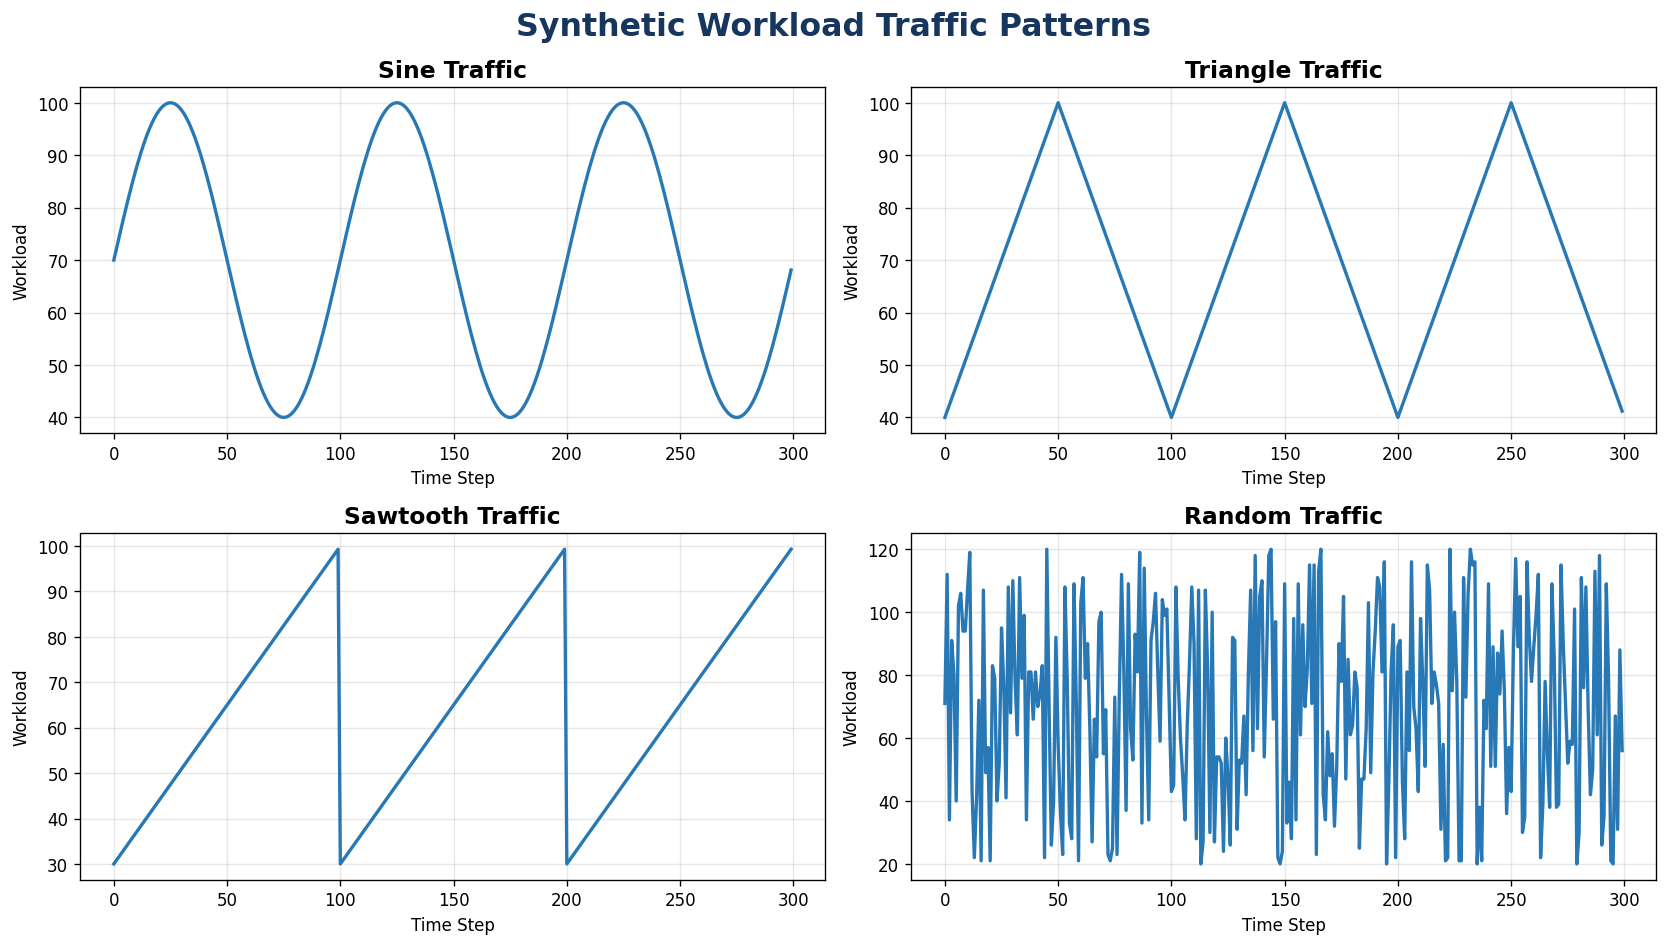

Gambar tersimpan: ppt_images/02_traffic_patterns.png


In [148]:
t = np.arange(1000)

sine = 70 + 30 * np.sin(2 * np.pi * t / 100)

triangle = 40 + 60 * (
    1 - np.abs(((t / 100) % 1) * 2 - 1)
)

sawtooth = 30 + 70 * ((t % 100) / 100)

np.random.seed(42)
random_traffic = np.random.randint(20, 121, size=1000)

datasets = [
    ("Sine Traffic", sine),
    ("Triangle Traffic", triangle),
    ("Sawtooth Traffic", sawtooth),
    ("Random Traffic", random_traffic)
]

fig, axes = plt.subplots(2, 2, figsize=(14, 8))

for ax, (name, data) in zip(axes.flatten(), datasets):
    ax.plot(data[:300], linewidth=2, color=BLUE)
    ax.set_title(name, fontsize=14, weight="bold")
    ax.set_xlabel("Time Step")
    ax.set_ylabel("Workload")
    ax.grid(alpha=0.3)

fig.suptitle(
    "Synthetic Workload Traffic Patterns",
    fontsize=19, weight="bold", color=NAVY
)

plt.tight_layout()
save_image(fig, "02_traffic_patterns.png")

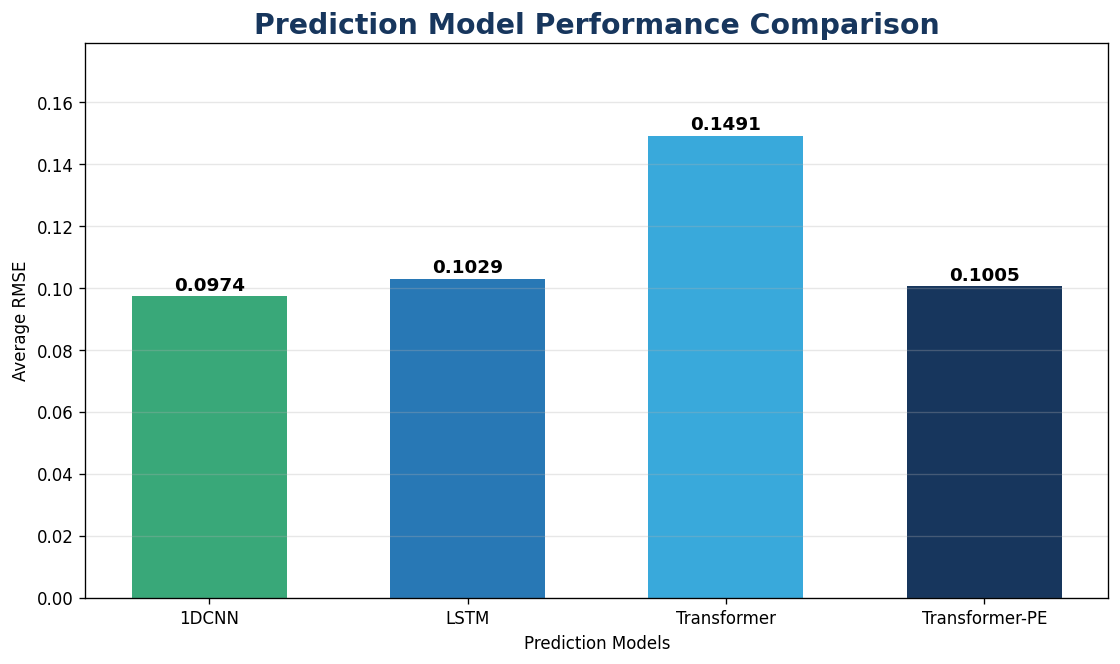

Gambar tersimpan: ppt_images/03_prediction_comparison.png


In [149]:
models = ["1DCNN", "LSTM", "Transformer", "Transformer-PE"]

rmse = [0.09735, 0.10288, 0.14910, 0.10050]

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.bar(
    models, rmse,
    color=[GREEN, BLUE, CYAN, NAVY],
    width=0.6
)

for bar, value in zip(bars, rmse):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.002,
        f"{value:.4f}",
        ha="center", fontsize=11, weight="bold"
    )

ax.set_title(
    "Prediction Model Performance Comparison",
    fontsize=17, weight="bold", color=NAVY
)
ax.set_ylabel("Average RMSE")
ax.set_xlabel("Prediction Models")
ax.grid(axis="y", alpha=0.3)
ax.set_ylim(0, max(rmse) * 1.2)

save_image(fig, "03_prediction_comparison.png")

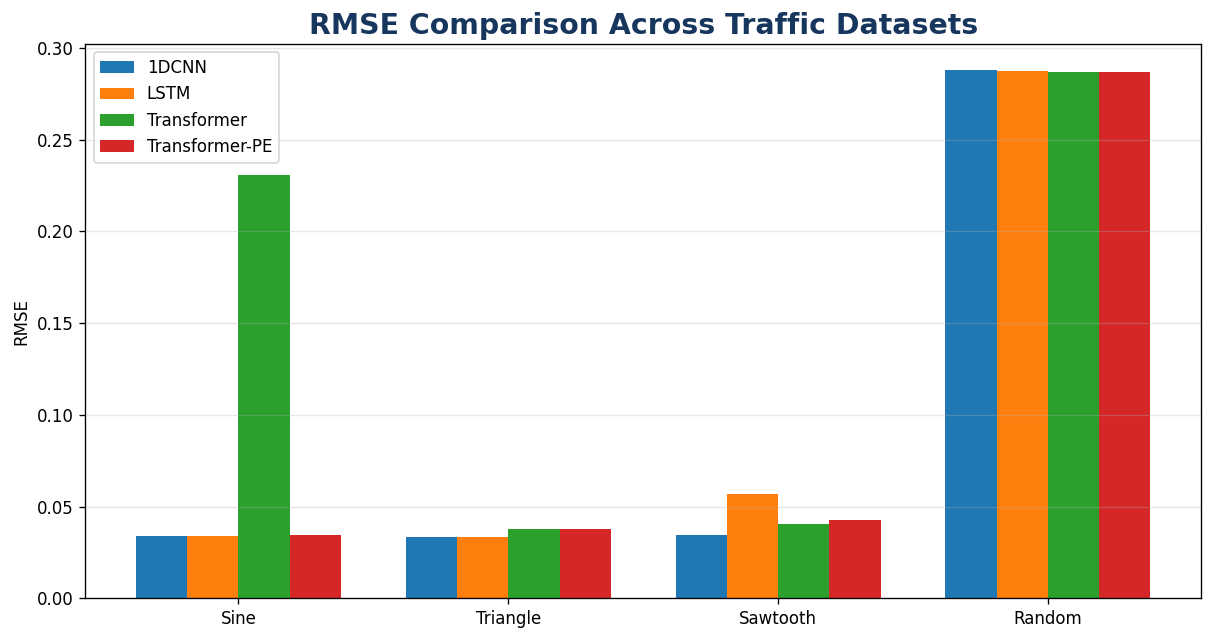

Gambar tersimpan: ppt_images/04_rmse_comparison.png


In [150]:
results = {
    "1DCNN": [0.033941, 0.033292, 0.034345, 0.287813],
    "LSTM": [0.034207, 0.033310, 0.056776, 0.287224],
    "Transformer": [0.230911, 0.038000, 0.040467, 0.287010],
    "Transformer-PE": [0.034577, 0.037532, 0.042899, 0.286989]
}

datasets = ["Sine", "Triangle", "Sawtooth", "Random"]

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(datasets))
width = 0.19

for i, (model, values) in enumerate(results.items()):
    ax.bar(
        x + (i - 1.5) * width,
        values,
        width,
        label=model
    )

ax.set_xticks(x)
ax.set_xticklabels(datasets)
ax.set_ylabel("RMSE")
ax.set_title(
    "RMSE Comparison Across Traffic Datasets",
    fontsize=17, weight="bold", color=NAVY
)
ax.legend()
ax.grid(axis="y", alpha=0.3)

save_image(fig, "04_rmse_comparison.png")

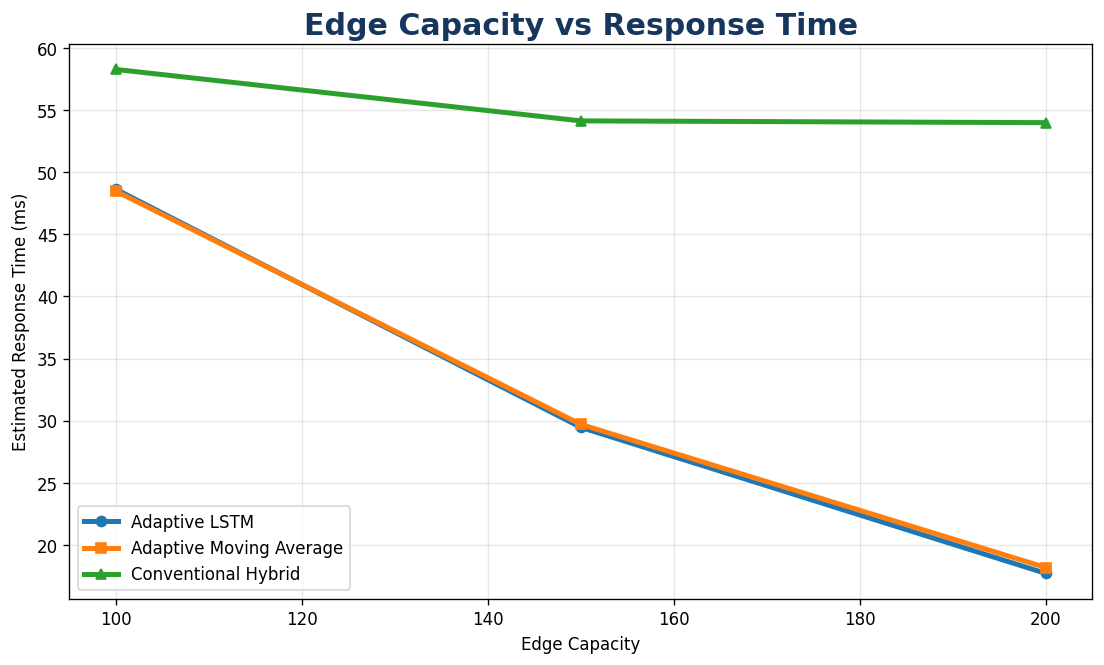

Gambar tersimpan: ppt_images/05_edge_capacity.png


In [151]:
capacity = [100, 150, 200]

lstm = [48.613666, 29.465106, 17.717578]
moving_average = [48.467754, 29.703776, 18.187739]
conventional = [58.254682, 54.119407, 53.977119]

fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(capacity, lstm, marker="o",
        linewidth=3, label="Adaptive LSTM")

ax.plot(capacity, moving_average, marker="s",
        linewidth=3, label="Adaptive Moving Average")

ax.plot(capacity, conventional, marker="^",
        linewidth=3, label="Conventional Hybrid")

ax.set_title(
    "Edge Capacity vs Response Time",
    fontsize=18, weight="bold", color=NAVY
)

ax.set_xlabel("Edge Capacity")
ax.set_ylabel("Estimated Response Time (ms)")
ax.legend()
ax.grid(alpha=0.3)

save_image(fig, "05_edge_capacity.png")